# Objectif 

Première analyse des données SBCEX 22. 

Données disponibles : 

* sus_posi_gps.mat: la position de tous les SUS durant la manip
* tossit_deploy_posi.mat: la position des tossits durant les SUS
* all_sus_sig.mat: tous les signaux des SUS que j'ai pu détecter sur tous les TOSSITs - il y a 1649 signaux (dans la variable y_pa_all), et vous avez des vecteurs (sus_n et tossit_n) qui vous donnent les numero de TOSSIT et SUS correspondant. Attention, dans sus_n, les SUS sont numérotes de 1 à 97, mais il s'agit en fait des SUS 106 à 202 (pour faire la correspondance avec les positions contenues dans sus_posi_gps.mat). Également, j'ai utilisé une moulinette automatique pour extraire les signaux, et je sais qu'il y a quelques erreurs.


Date de création : 20/08/2026

In [21]:
import os
import sys
import numpy as np
import xarray as xr 
import pandas as pd
import soundfile as sf
import scipy.signal as sp
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates

from scipy.io import loadmat
from datetime import datetime, timedelta

project_root = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
sys.path.append(
    project_root
)  # \real_data_analysis\fiberscope_groix\src\data_processing
root_data = (
    r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\sbcex22\data"
)
root_bathy_data = os.path.join(project_root, "data", "bathy")
from publication.publication_figure import PubFigure, set_subfigures_abc_labels
PubFigure()

In [22]:
root_sbcex22_data = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\data\SBCEX22"
f_src_pos = "sus_posi_gps.mat"
fpath_src_pos = os.path.join(root_sbcex22_data, f_src_pos)
f_rcv_pos = "tossit_deploy_posi.mat"
fpath_rcv_path = os.path.join(root_sbcex22_data, f_rcv_pos)
f_sig = "all_sus_sig.mat"
fpath_sig = os.path.join(root_sbcex22_data, f_sig)

# Load data 

In [23]:
src_pos_mat = loadmat(fpath_src_pos)
src_pos = {
    "lon": src_pos_mat["lon"].flatten(),
    "lat": src_pos_mat["lat"].flatten(),
    "time_num": src_pos_mat["time_num"].flatten(),
    "time_str": src_pos_mat["time_str"].flatten(),
}
src_pos["datetime"] = pd.to_datetime(src_pos["time_str"])

In [24]:
src_pos

{'lon': array([-70.52791667, -70.52638333, -70.5252    , -70.52403333,
        -70.52285   , -70.52166667, -70.52048333, -70.51933333,
        -70.51815   , -70.51696667, -71.5158    , -70.51461667,
        -70.51343333, -70.51225   , -70.51108333, -70.4907    ,
        -70.49068333, -70.49068333, -70.50108333, -70.50108333,
        -70.50108333, -70.51165   , -70.51165   , -70.51166667,
        -70.52138333, -70.5214    , -70.52133333, -70.53215   ,
        -70.53221667, -70.53223333, -70.54258333, -70.54263333,
        -70.54256667, -70.55301667, -70.55298333, -70.55298333,
        -70.57391667, -70.5739    , -70.57388333, -70.58411667,
        -70.5841    , -70.58411667, -70.59475   , -70.59475   ,
        -70.59475   , -70.60548333, -70.6055    , -70.6055    ,
        -70.61561667, -70.61563333, -70.6156    , -70.62618333,
        -70.62618333, -70.6262    , -70.63645   , -70.63645   ,
        -70.63645   , -70.64661667, -70.6466    , -70.64661667,
        -70.65718333, -70.6571666

In [25]:
rcv_pos_mat = loadmat(fpath_rcv_path)
rcv_pos = {
    "lon": rcv_pos_mat["lon"].flatten(),
    "lat": rcv_pos_mat["lat"].flatten(),
}

In [26]:
rcv_pos

{'lon': array([-70.566698, -70.506121, -70.491334, -70.622257, -70.637745,
        -70.51387 , -70.501086, -70.49835 , -70.481145, -70.629626,
        -70.648099, -70.566589, -70.566839, -70.593661, -70.534079,
        -70.65404 , -70.540836, -70.596323, -70.677109, -70.610324]),
 'lat': array([40.460018, 40.436261, 40.430387, 40.482485, 40.488835, 40.491857,
        40.500288, 40.459054, 40.459757, 40.458698, 40.457744, 40.509126,
        40.521704, 40.470924, 40.447381, 40.495575, 40.476035, 40.440739,
        40.297949, 40.280783])}

In [27]:
sig_mat = loadmat(fpath_sig)
sig = {
    "range": sig_mat["range"],
    "sus_n": sig_mat["sus_n"],
    "tossit_n": sig_mat["tossit_n"],
    "y_pa_all": sig_mat["y_pa_all"],
}


In [28]:
sig

{'range': array([[3163.38226175, 3161.30337997, 3160.26505201, ..., 4012.05868467,
         4009.60405926, 4011.98114849]]),
 'sus_n': array([[ 1,  2,  3, ..., 95, 96, 97]], dtype=uint8),
 'tossit_n': array([[ 1,  1,  1, ..., 18, 18, 18]], dtype=uint8),
 'y_pa_all': array([[ 1.28901177,  0.23489836,  0.40942358, ...,  0.26871519,
          0.18935084,  0.75731172],
        [ 1.28901177,  0.32291202,  0.40942358, ...,  0.26871519,
          0.18935084,  0.75731172],
        [ 1.28901177,  0.32291202,  0.49743724, ...,  0.26871519,
          0.18935084,  0.8385106 ],
        ...,
        [ 1.28901177, -0.73325186, -2.58304075, ...,  0.67470962,
         -0.29784247, -0.13587601],
        [ 1.37702543, -0.73325186, -2.67105441, ...,  0.59351073,
         -0.29784247, -0.13587601],
        [ 1.46503909, -0.82126552, -2.75906806, ...,  0.51231185,
         -0.29784247, -0.13587601]])}

In [29]:
print("Source position")
for k in src_pos.keys():
    print(f"{k} : {src_pos[k].shape}")
print("Receiver position")
for k in rcv_pos.keys():
    print(f"{k} : {rcv_pos[k].shape}")
print("Signal")
for k in sig.keys():
    print(f"{k} : {sig[k].shape}")

Source position
lon : (267,)
lat : (267,)
time_num : (267,)
time_str : (267,)
datetime : (267,)
Receiver position
lon : (20,)
lat : (20,)
Signal
range : (1, 1649)
sus_n : (1, 1649)
tossit_n : (1, 1649)
y_pa_all : (96001, 1649)


In [30]:
# Correct the sus_n 
sig["sus_n"] += 105 
sig["sus_n"]

array([[106, 107, 108, ..., 200, 201, 202]], dtype=uint8)

In [31]:
fs = 24 * 1e3
ds_sig = xr.Dataset(
    data_vars=dict(
        s=(["t", "id"], sig["y_pa_all"]),
        range=("id", sig["range"].flatten()),
        sus_n=("id", sig["sus_n"].flatten()),
        tossit_n=("id", sig["tossit_n"].flatten()),
    ),
    coords=dict(
        t=("t", np.arange(sig["y_pa_all"].shape[0]) * 1/fs),
        id=("id", np.arange(sig["y_pa_all"].shape[1])),
    ),
)
ds_sig

<xarray.Dataset> Size: 1GB
Dimensions:   (t: 96001, id: 1649)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 7kB 0 1 2 3 4 5 6 ... 1643 1644 1645 1646 1647 1648
Data variables:
    s         (t, id) float64 1GB 1.289 0.2349 0.4094 ... 0.5123 -0.2978 -0.1359
    range     (id) float64 13kB 3.163e+03 3.161e+03 ... 4.01e+03 4.012e+03
    sus_n     (id) uint8 2kB 106 107 108 109 110 111 ... 197 198 199 200 201 202
    tossit_n  (id) uint8 2kB 1 1 1 1 1 1 1 1 1 1 ... 18 18 18 18 18 18 18 18 18

In [32]:
nrcv = rcv_pos["lon"].size
nsrc_pos = src_pos["lon"].size
ndetection = sig["range"].size

In [33]:
rcv_id = np.arange(1, nrcv+1)
rcv_pos["id"] = rcv_id
rcv_pos = pd.DataFrame.from_dict(rcv_pos)
rcv_pos = rcv_pos.set_index("id")
rcv_pos

,lon,lat
id,,
1,-70.566698,40.460018
2,-70.506121,40.436261
3,-70.491334,40.430387
4,-70.622257,40.482485
5,-70.637745,40.488835
6,-70.513870,40.491857
7,-70.501086,40.500288
8,-70.498350,40.459054
9,-70.481145,40.459757


In [34]:
# Les signaux du fichiers all_sus_sig.mat sont les signaux des tossits du CMP de 1 à 18 (sans le 8) -> on vire les autres
idx_to_keep = [idx for idx in rcv_pos.index if idx in np.unique(ds_sig.tossit_n.values)]
rcv_pos = rcv_pos.loc[idx_to_keep]
rcv_pos

,lon,lat
id,,
1,-70.566698,40.460018
2,-70.506121,40.436261
3,-70.491334,40.430387
4,-70.622257,40.482485
5,-70.637745,40.488835
6,-70.513870,40.491857
7,-70.501086,40.500288
9,-70.481145,40.459757
10,-70.629626,40.458698


In [35]:
src_pos_id = np.arange(1, nsrc_pos + 1)
src_pos["id"] = src_pos_id
src_pos = pd.DataFrame.from_dict(src_pos)
src_pos = src_pos.set_index("id")
src_pos

,lon,lat,time_num,time_str,datetime
id,,,,,
1,-70.527917,40.437250,739751.636214,14-May-2025 15:16:08,2025-05-14 15:16:08
2,-70.526383,40.437550,739751.641714,14-May-2025 15:24:04,2025-05-14 15:24:04
3,-70.525200,40.437533,739751.646412,14-May-2025 15:30:50,2025-05-14 15:30:50
4,-70.524033,40.437550,739751.651867,14-May-2025 15:38:41,2025-05-14 15:38:41
5,-70.522850,40.437533,739751.656140,14-May-2025 15:44:50,2025-05-14 15:44:50
...,...,...,...,...,...
263,-70.746350,40.203733,739755.884340,18-May-2025 21:13:27,2025-05-18 21:13:27
264,-70.746367,40.203717,739755.884827,18-May-2025 21:14:09,2025-05-18 21:14:09
265,-70.746367,40.203717,739755.885275,18-May-2025 21:14:47,2025-05-18 21:14:47


In [36]:
# Les signaux du fichiers all_sus_sig.mat sont les signaux émissions de 106 à 202 -> on vire les autres
idx_to_keep = [idx for idx in src_pos.index if idx in np.unique(ds_sig.sus_n.values)]
src_pos = src_pos.loc[idx_to_keep]
src_pos = src_pos.loc[idx_to_keep]
src_pos

,lon,lat,time_num,time_str,datetime
id,,,,,
106,-70.535850,40.476033,739752.963205,15-May-2025 23:07:00,2025-05-15 23:07:00
107,-70.535850,40.476000,739752.963784,15-May-2025 23:07:50,2025-05-15 23:07:50
108,-70.535850,40.475983,739752.964379,15-May-2025 23:08:42,2025-05-15 23:08:42
109,-70.526750,40.481867,739752.974043,15-May-2025 23:22:37,2025-05-15 23:22:37
110,-70.526717,40.481833,739752.974724,15-May-2025 23:23:36,2025-05-15 23:23:36
...,...,...,...,...,...
198,-70.557800,40.461700,739756.481431,19-May-2025 11:33:15,2025-05-19 11:33:15
199,-70.557800,40.461700,739756.481811,19-May-2025 11:33:48,2025-05-19 11:33:48
200,-70.557800,40.461700,739756.482493,19-May-2025 11:34:47,2025-05-19 11:34:47


Text(0, 0.5, 'Latitude [°]')

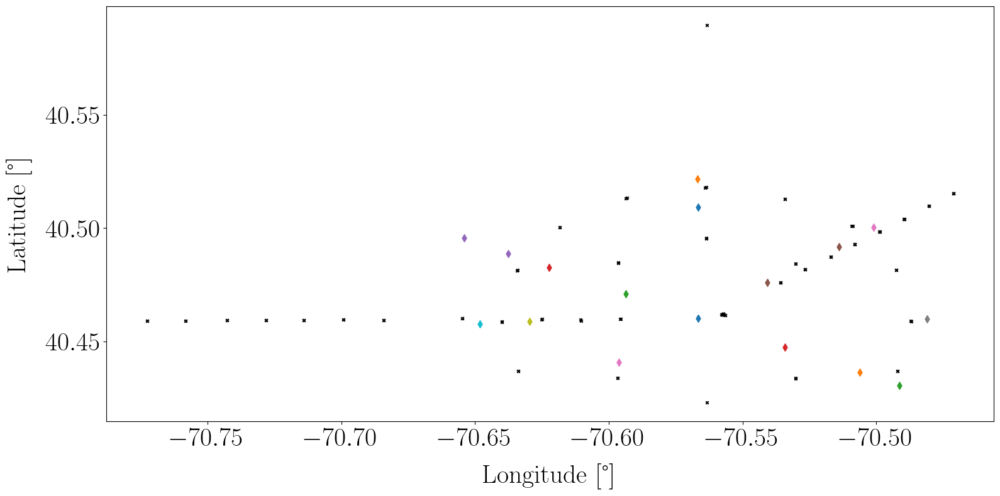

In [37]:
plt.figure()
for rcv_id in rcv_pos.index:
    rcv_i = rcv_pos.loc[rcv_id]
    plt.scatter(rcv_i.lon, rcv_i.lat, marker="d", label=f"T{rcv_id}")

# Plot source pos 
plt.scatter(src_pos.lon, src_pos.lat, color="k", marker="x", s=10)
# plt.scatter(obs4_lon, obs4_lat, marker="d", color="r", label="OBS 4")
# plt.scatter(obs7_lon, obs7_lat, marker="d", color="g", label="OBS 7")
# sc = plt.scatter(lon_pos, lat_pos, cmap="jet", c=np.arange(lat_pos.size), marker="x", s=10)
# plt.colorbar(sc, label="Source position")
# plt.legend(fontsize=10)
plt.xlabel("Longitude [°]")
plt.ylabel("Latitude [°]")

In [38]:
from source.utils.utils_bathy import load_bathy

rcv_center = rcv_pos.loc[1]
bathy = load_bathy(
    rcv_center.lon,
    rcv_center.lat,
    dlon_box=1,
    dlat_box=1,
)

# Build bathy dataset
ds_bathy = xr.Dataset(
    data_vars=dict(
        elevation=(["lat", "lon"], bathy.elevation.values),
    ),
    coords=dict(
        lon=bathy.lon.values,
        lat=bathy.lat.values,
    ),
    attrs=dict(
        description="Bathymetry data from GEBCO 2021",
        geodesic_frame="WGS84",
    ),
)

# Add attributes to variables
ds_bathy.elevation.attrs["units"] = "m"
ds_bathy.lon.attrs["units"] = "°"
ds_bathy.lat.attrs["units"] = "°"
ds_bathy.elevation.attrs["long_name"] = "Elevation (WGS84)"
ds_bathy.lon.attrs["long_name"] = "Longitude"
ds_bathy.lat.attrs["long_name"] = "Latitude"

# Save to netCDF
fname = "bathy.nc"
fpath = os.path.join(root_data, fname)
ds_bathy.to_netcdf(fpath)

In [39]:
ds_bathy

<xarray.Dataset> Size: 119kB
Dimensions:    (lat: 240, lon: 240)
Coordinates:
  * lat        (lat) float64 2kB 39.96 39.96 39.97 39.97 ... 40.95 40.95 40.96
  * lon        (lon) float64 2kB -71.06 -71.06 -71.06 ... -70.08 -70.07 -70.07
Data variables:
    elevation  (lat, lon) int16 115kB -408 -412 -415 -417 ... -17 -17 -18 -18
Attributes:
    description:     Bathymetry data from GEBCO 2021
    geodesic_frame:  WGS84

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_38644\2998139566.py:113: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


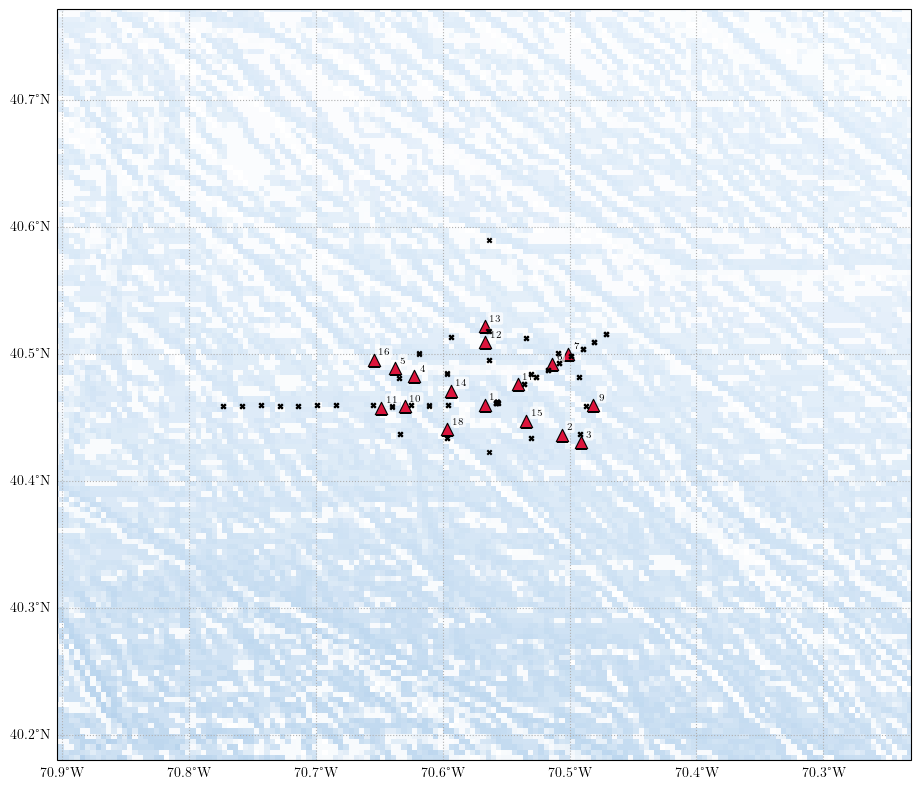

In [40]:
import numpy as np
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle

# Extract data
z = ds_bathy["elevation"].values
lon = ds_bathy["lon"].values
lat = ds_bathy["lat"].values

# Receiver dataset
rx_lon = rcv_pos.lon
rx_lat = rcv_pos.lat
rx_id = rcv_pos.index

pad = 0.25  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)

# Hillshade
ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Shaded bathymetry
ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Optional depth contours
levels = np.arange(np.floor(z.min() / 100) * 100, 0, 1000)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.4,
    alpha=1,
    transform=ccrs.PlateCarree(),
)

ax.clabel(cs, fmt="%d m", fontsize=7)

# Coastlines
ax.coastlines(resolution="10m", linewidth=1)
ax.add_feature(cfeature.LAND, facecolor="lightgray")

# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )

# Zoom on the area of interest
ax.set_extent(zoom_extent)

# Source positions
sc = ax.scatter(src_pos.lon, src_pos.lat, color="k", marker="x", s=10, zorder=12)

plt.tight_layout()


# plt.show()

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_38644\2299934014.py:82: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


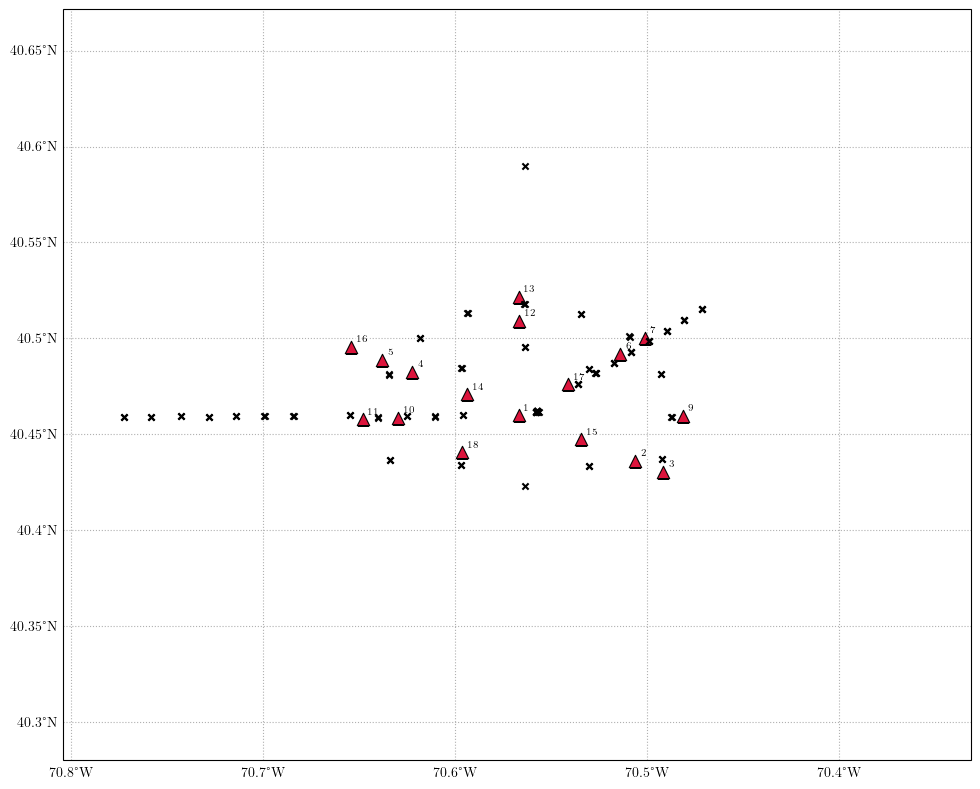

In [126]:
import numpy as np
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle

# Extract data
z = ds_bathy["elevation"].values
lon = ds_bathy["lon"].values
lat = ds_bathy["lat"].values

# Receiver dataset
rx_lon = rcv_pos.lon
rx_lat = rcv_pos.lat
rx_id = rcv_pos.index

pad = 0.15  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )

# Zoom on the area of interest
ax.set_extent(zoom_extent)

# Source positions
sc = ax.scatter(src_pos.lon, src_pos.lat, color="k", marker="x", s=20, zorder=12)

plt.tight_layout()


# plt.show()

# Visualisation de quelques émissions  

In [41]:
# ds_sig

<xarray.Dataset> Size: 1GB
Dimensions:   (t: 96001, id: 1649)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 7kB 0 1 2 3 4 5 6 ... 1643 1644 1645 1646 1647 1648
Data variables:
    s         (t, id) float64 1GB 1.289 0.2349 0.4094 ... 0.5123 -0.2978 -0.1359
    range     (id) float64 13kB 3.163e+03 3.161e+03 ... 4.01e+03 4.012e+03
    sus_n     (id) uint8 2kB 106 107 108 109 110 111 ... 197 198 199 200 201 202
    tossit_n  (id) uint8 2kB 1 1 1 1 1 1 1 1 1 1 ... 18 18 18 18 18 18 18 18 18

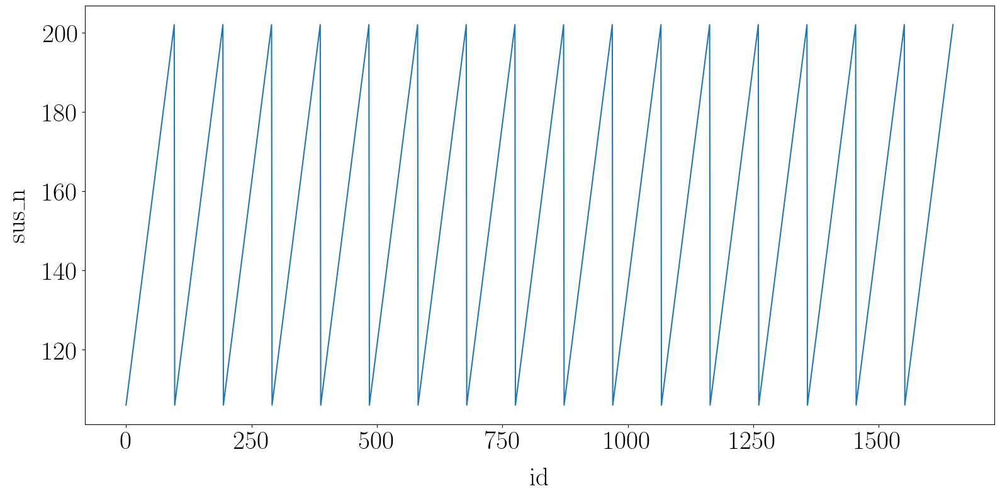

In [42]:
# ds_sig.sus_n.plot()

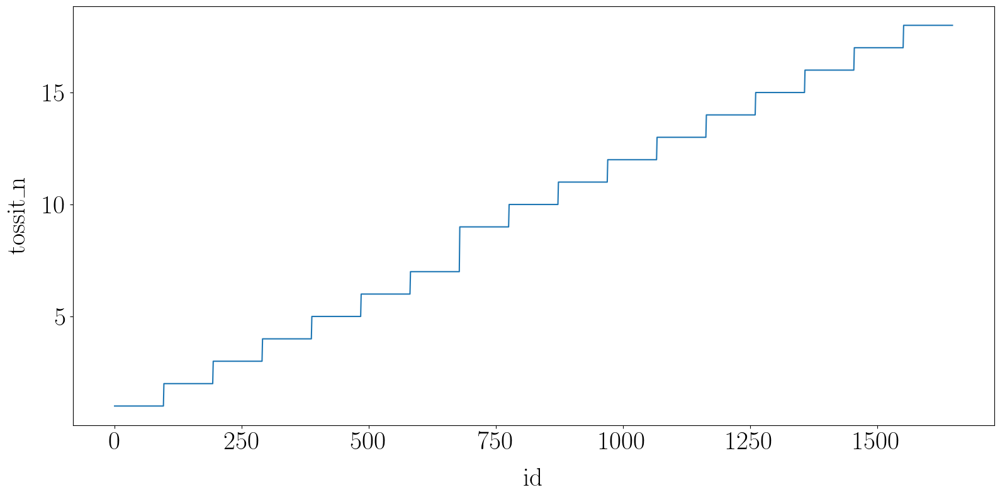

In [43]:
# ds_sig.tossit_n.plot()

Les signaux de all_sus_sig.mat sont les signaux qui ont été détectés sur l'ensemble des capteurs du CMP (1 à 18). Le capteur 8 est exclue.  

## Sélection d'une émisssion 

In [44]:
r_dispersion = []
r_max = []
r_min = []
for sus_n in ds_sig.sus_n.values:
    id_sus_n = ds_sig.id.values[ds_sig.sus_n == sus_n]
    ds_sus_n = ds_sig.sel(id=id_sus_n)
    r_disp = ds_sus_n.range.max() - ds_sus_n.range.min()
    r_dispersion.append(r_disp.values)
    r_max.append(ds_sus_n.range.max().values)
    r_min.append(ds_sus_n.range.min().values)

r_dispersion = np.array(r_dispersion)
r_max = np.array(r_max)
r_min = np.array(r_min)
print(r_dispersion)
print(r_max)
print(r_min)

[9830.27109387 9831.0396127  9831.41219999 ... 8208.390555   8206.28944756
 8207.25627061]
[10253.0735712  10253.8600168  10254.25371802 ...  8985.86061969
  8979.1755344   8983.80157232]
[422.80247733 422.8204041  422.84151804 ... 777.47006468 772.88608683
 776.54530171]


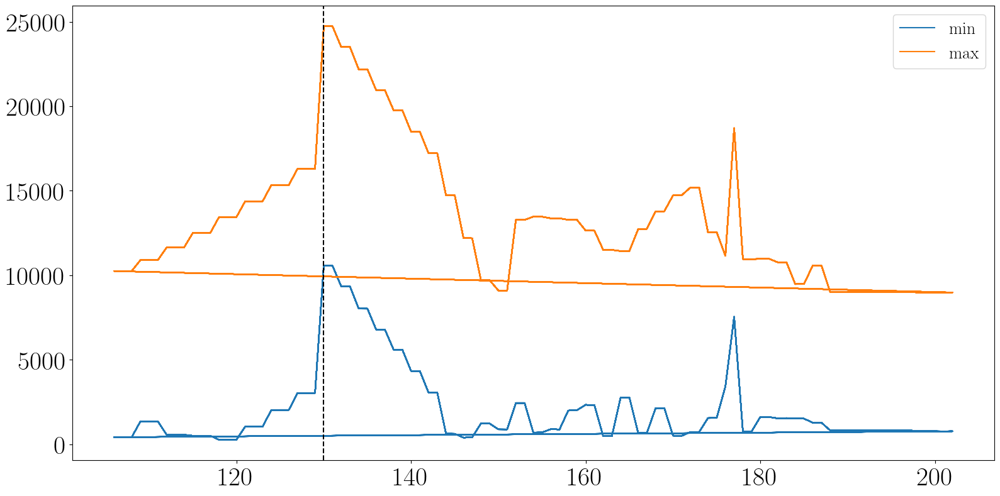

In [45]:
plt.plot(ds_sig.sus_n.values, r_min, label="min")
plt.plot(ds_sig.sus_n.values, r_max, label="max")
plt.legend()
plt.axvline(130, color="k", linestyle="--")

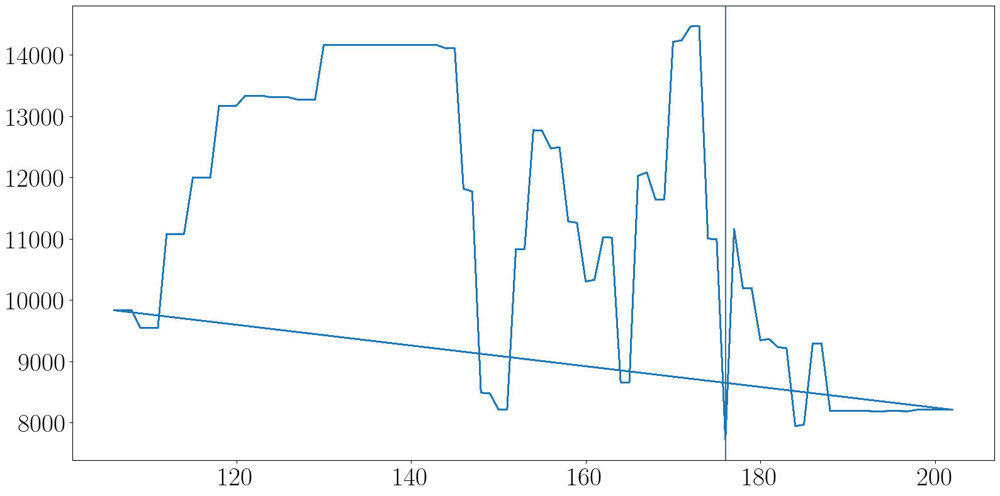

In [46]:
plt.plot(ds_sig.sus_n.values, r_dispersion, label="dispersion")
plt.axvline(x=176)

In [47]:
sus_n_visu = [110, 122, 130, 150]
idx_to_keep = np.array([ds_sig.id.values[ds_sig.sus_n == sus_n] for sus_n in sus_n_visu]).flatten()
# print(idx_to_keep)
ds_visu = ds_sig.sel(id=idx_to_keep)
ds_visu

<xarray.Dataset> Size: 92MB
Dimensions:   (t: 96001, id: 119)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 476B 4 101 198 295 392 489 ... 1208 1305 1402 1499 1596
Data variables:
    s         (t, id) float64 91MB -1.702 0.3153 0.9279 ... 1.251 -0.06477
    range     (id) float64 952B 4.167e+03 5.354e+03 ... 2.083e+03 4.098e+03
    sus_n     (id) uint8 119B 110 110 110 110 110 110 ... 150 150 150 150 150
    tossit_n  (id) uint8 119B 1 2 3 4 5 6 7 9 10 ... 10 11 12 13 14 15 16 17 18

In [48]:
src_pos_visu = src_pos.loc[sus_n_visu]
src_pos_visu

,lon,lat,time_num,time_str,datetime
id,,,,,
110,-70.526717,40.481833,739752.974724,15-May-2025 23:23:36,2025-05-15 23:23:36
122,-70.489617,40.503967,739753.014353,16-May-2025 00:20:40,2025-05-16 00:20:40
130,-70.772667,40.459017,739753.902799,16-May-2025 21:40:01,2025-05-16 21:40:01
131,-70.772683,40.459033,739753.903454,16-May-2025 21:40:58,2025-05-16 21:40:58
132,-70.758233,40.459000,739753.914896,16-May-2025 21:57:26,2025-05-16 21:57:26
133,-70.758233,40.459000,739753.915479,16-May-2025 21:58:17,2025-05-16 21:58:17
150,-70.556417,40.461533,739754.047587,17-May-2025 01:08:31,2025-05-17 01:08:31


In [ ]:
# Plot source position for selected ranges
pad = 0.15  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


z = bathy_zoom["elevation"].values
lon = bathy_zoom["lon"].values
lat = bathy_zoom["lat"].values

# # Hillshade
# ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
# rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )

# Zoom on the area of interest
ax.set_extent(zoom_extent)

# Source positions
for sus_n in sus_n_visu:
    src_i = src_pos.loc[sus_n]
    ax.scatter(src_i.lon, src_i.lat, marker="x", s=30, label=f"SUS {sus_n}")

# sc = ax.scatter(src_pos_visu.lon, src_pos_visu.lat, , marker="x", s=12)
# plt.colorbar(sc)
# plt.tight_layout()

plt.legend(fontsize=18, ncol=2)

# plt.show()
# plt.xlim(70.8, 70.7)

(70.8, 70.7)

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\events.py:96: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making

In [50]:
# Choix des récepteurs à visualiser
tossit_n_visu = [16, 13, 7, 3, 1, 4, 17, 15]
idx_to_keep = np.array(
    [ds_visu.id.values[ds_visu.tossit_n == tossit_n] for tossit_n in tossit_n_visu]
).flatten()
ds_visu = ds_visu.sel(id=idx_to_keep)
ds_visu

<xarray.Dataset> Size: 44MB
Dimensions:   (t: 96001, id: 56)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 224B 1362 1374 1382 1383 1384 ... 1286 1287 1288 1305
Data variables:
    s         (t, id) float64 43MB 1.918 -1.525 1.063 ... 0.2328 -1.486 -1.199
    range     (id) float64 448B 1.09e+04 1.397e+04 ... 1.906e+04 2.462e+03
    sus_n     (id) uint8 56B 110 122 130 131 132 133 ... 122 130 131 132 133 150
    tossit_n  (id) uint8 56B 16 16 16 16 16 16 16 13 ... 17 15 15 15 15 15 15 15

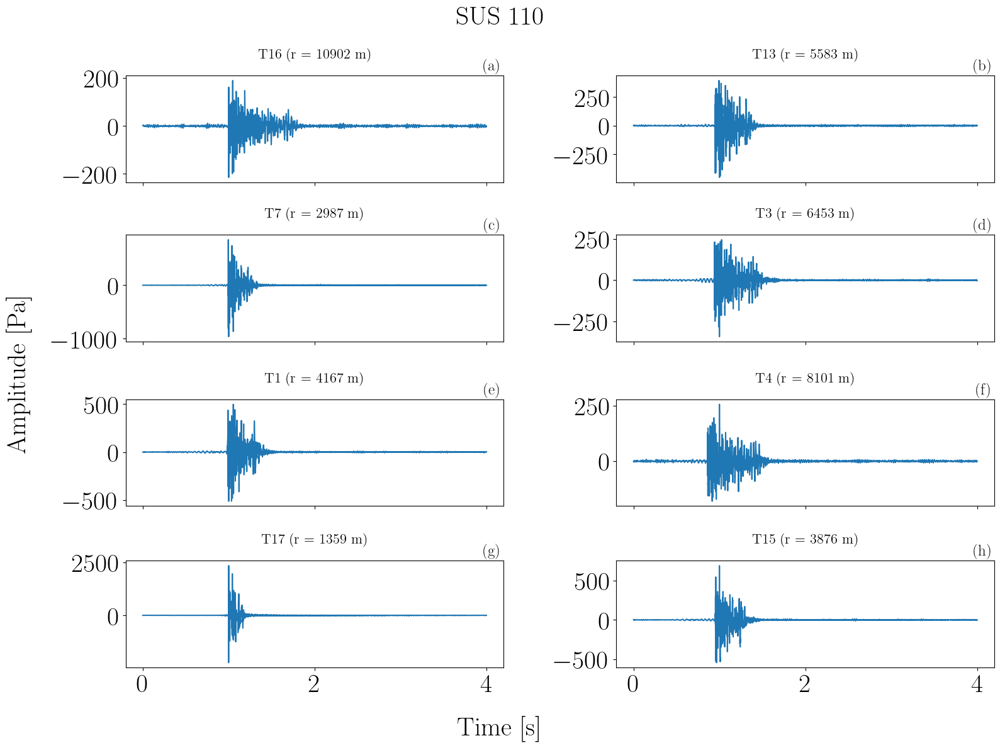

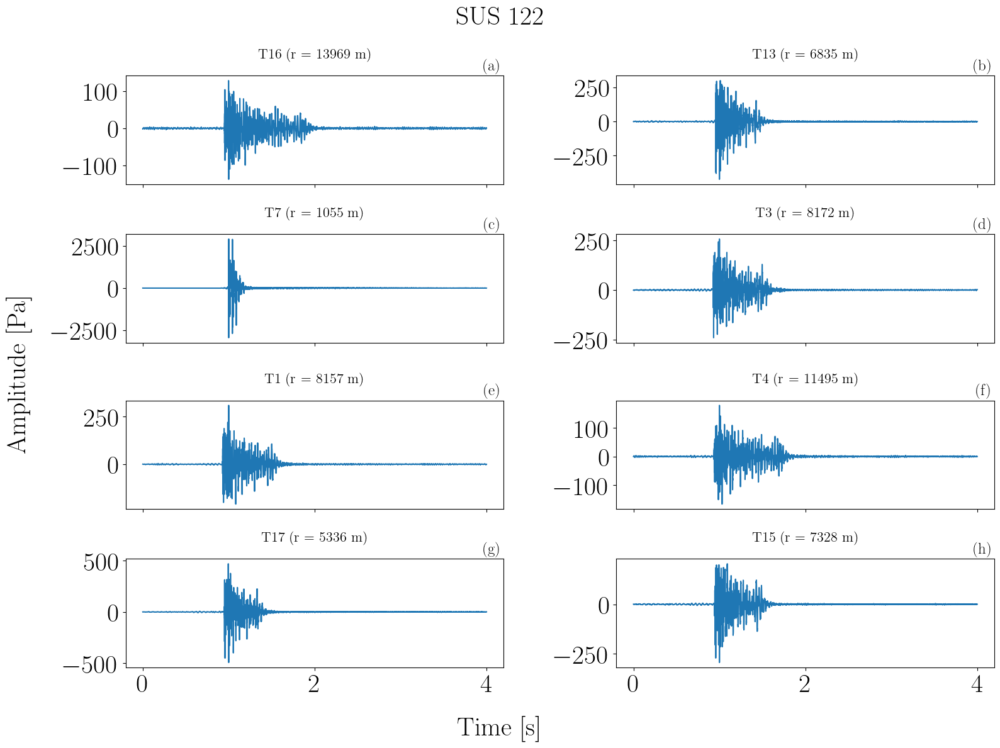

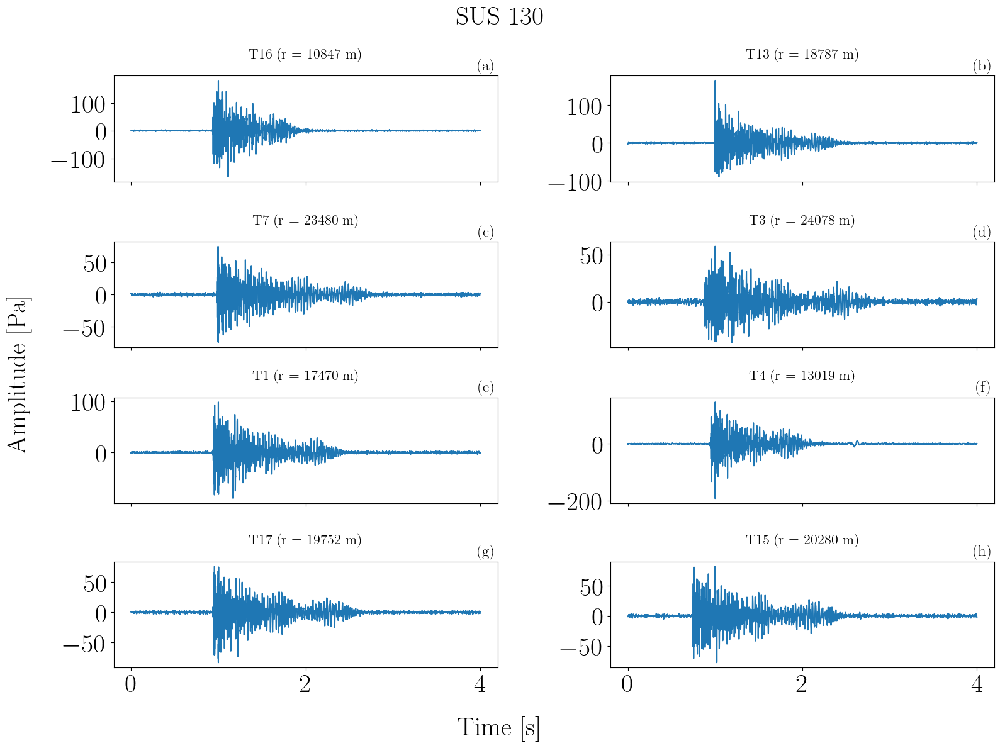

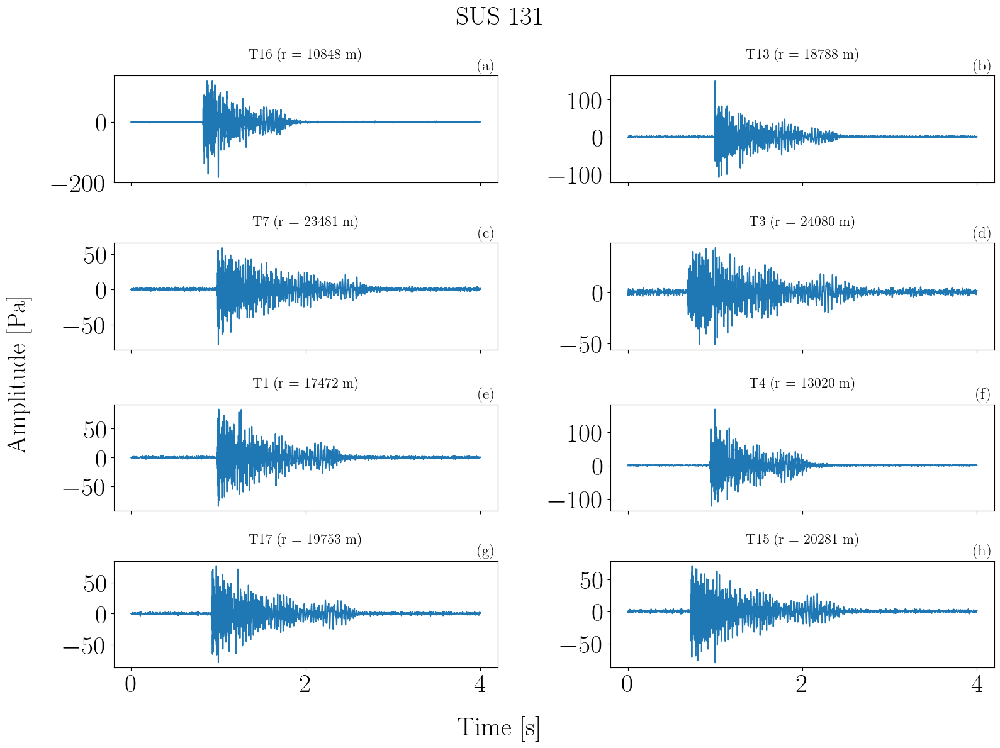

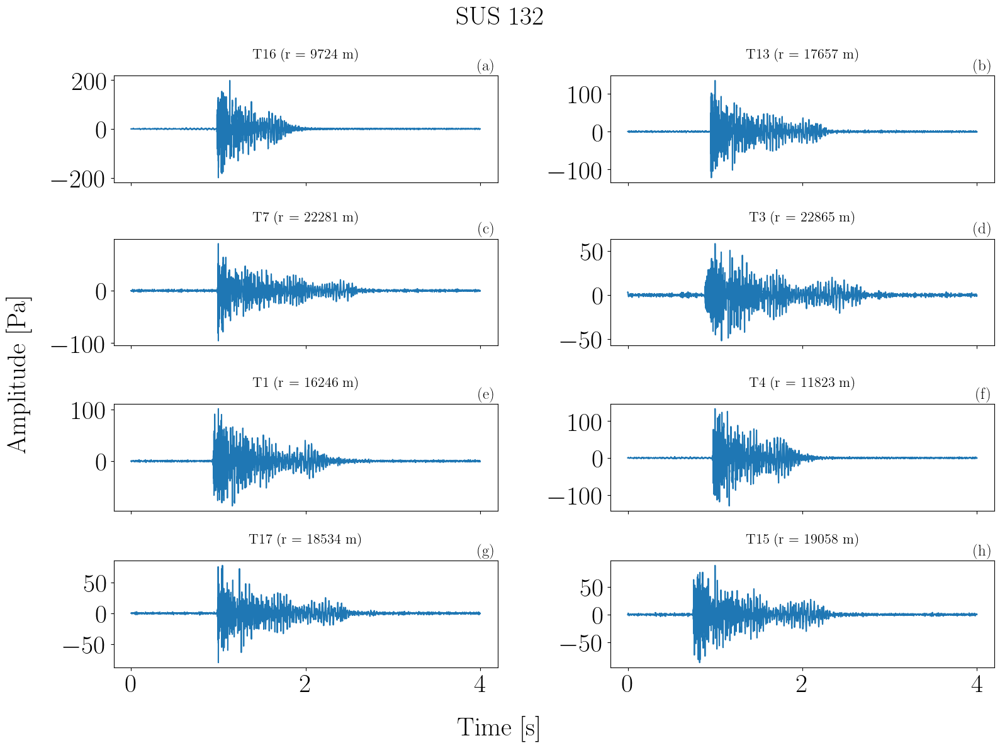

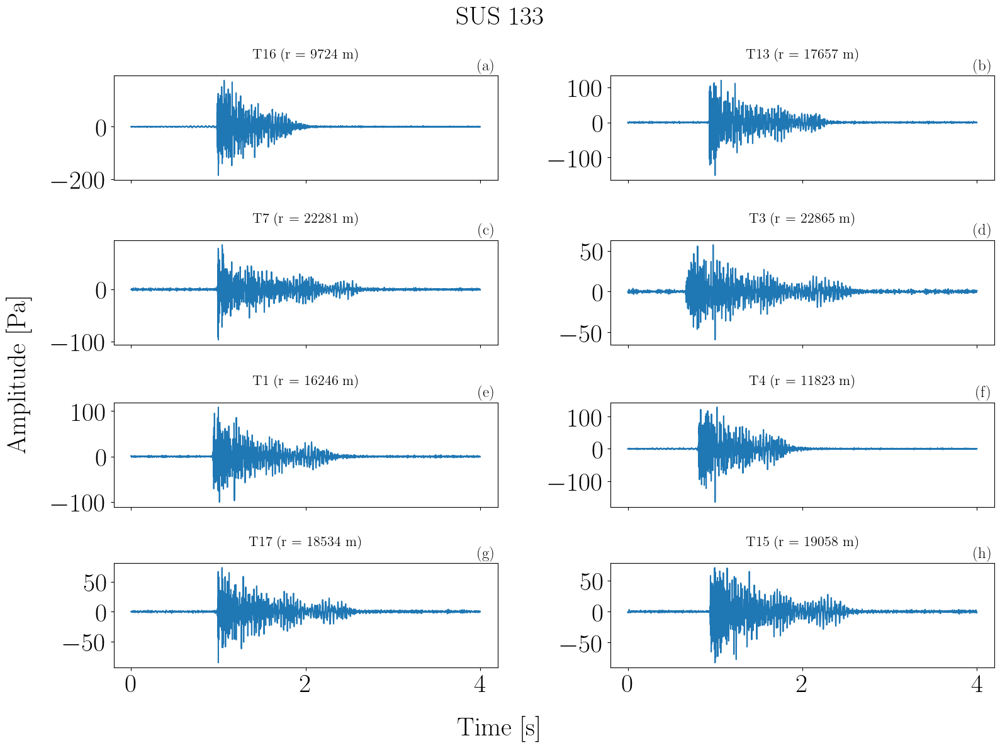

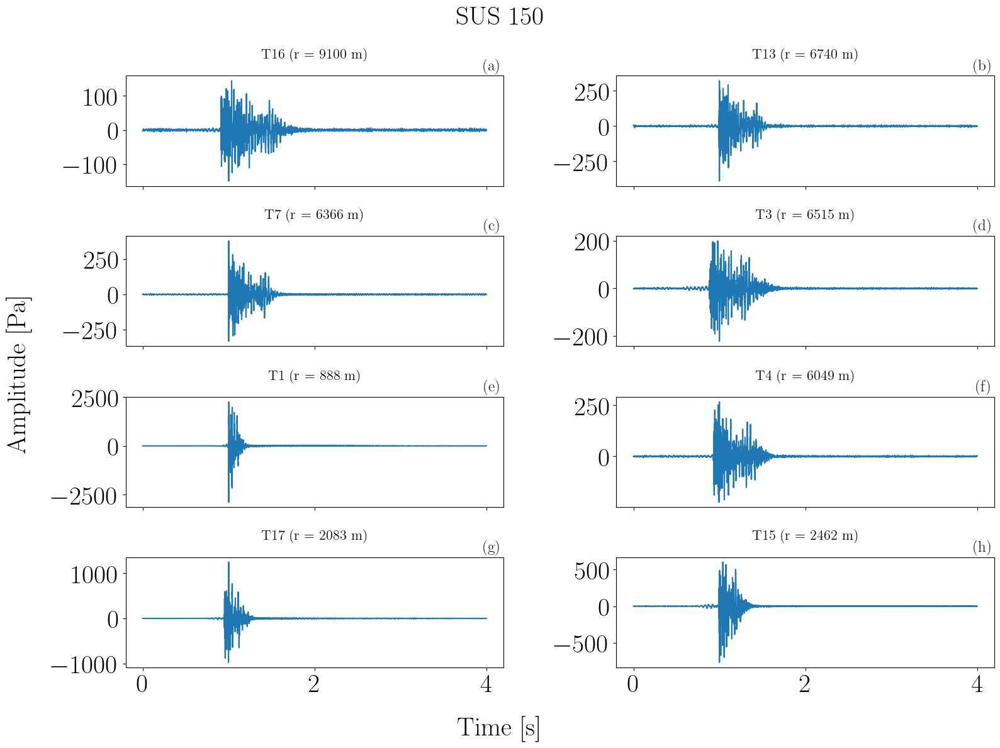

In [51]:
# Affichage des signaux pour chaque source
for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)
    # print(ds_sus_n)

    fig, axs = plt.subplots(
        nrows=len(tossit_n_visu) // 2,
        ncols=2,
        figsize=(16, 12),
        sharex=True,
        sharey=False,
    )
    # plt.figure(figsize=(12, 8))
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        ds_tossit_n.s.plot(ax=ax, label=f"T{tossit_n}")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(f"T{tossit_n} (r = {ds_tossit_n.range.values[0]:.0f} m)", fontsize=16)

    fig.suptitle(f"SUS {sus_n}")
    fig.supxlabel("Time [s]")
    fig.supylabel("Amplitude [Pa]")

    set_subfigures_abc_labels(
        axs=axs,
        fontsize=18,
        x_pos=0.995,
        y_pos=1.02,
        ha="right",
        va="bottom",
    )

In [52]:
20 * np.log10(np.max(ds_visu.s.values, axis=0) / 1e-5)

array([145.56094083, 142.14990016, 145.15450507, 142.84940886,
       145.91864899, 144.93822349, 143.17974936, 151.90391958,
       149.55132089, 144.36587507, 143.62517345, 142.60065835,
       141.60079415, 150.16034481, 158.62862917, 169.26680731,
       137.45637182, 135.42191902, 139.06787922, 138.65287372,
       151.57913832, 147.77810316, 148.21232594, 135.3636542 ,
       132.70019877, 135.32491263, 135.15699701, 146.02558992,
       153.95601036, 149.78636833, 139.82568682, 138.46037317,
       140.08789328, 140.70821702, 167.04382114, 148.16431504,
       145.04015252, 143.30429375, 144.49189269, 142.47770412,
       142.22714741, 148.51061933, 167.40149975, 153.42295766,
       137.64150773, 137.69642449, 137.79576354, 137.32512626,
       161.93151759, 156.75372088, 146.22537663, 138.3251641 ,
       137.01533797, 138.99273282, 137.01567264, 155.58391862])

nperseg = 51, noverlap = 50


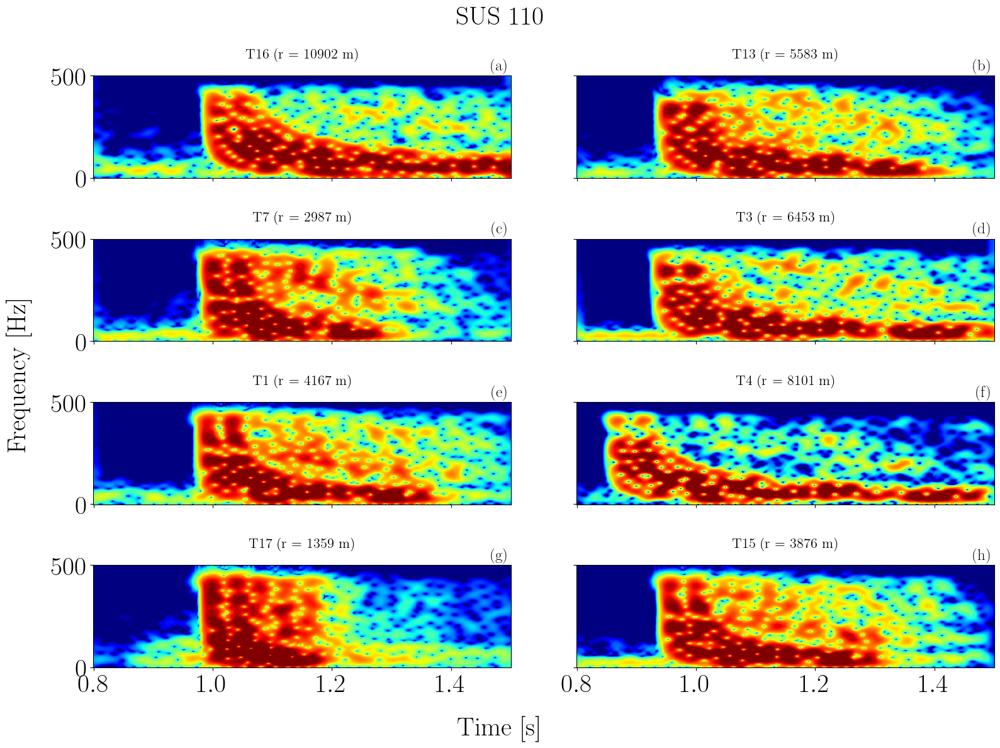

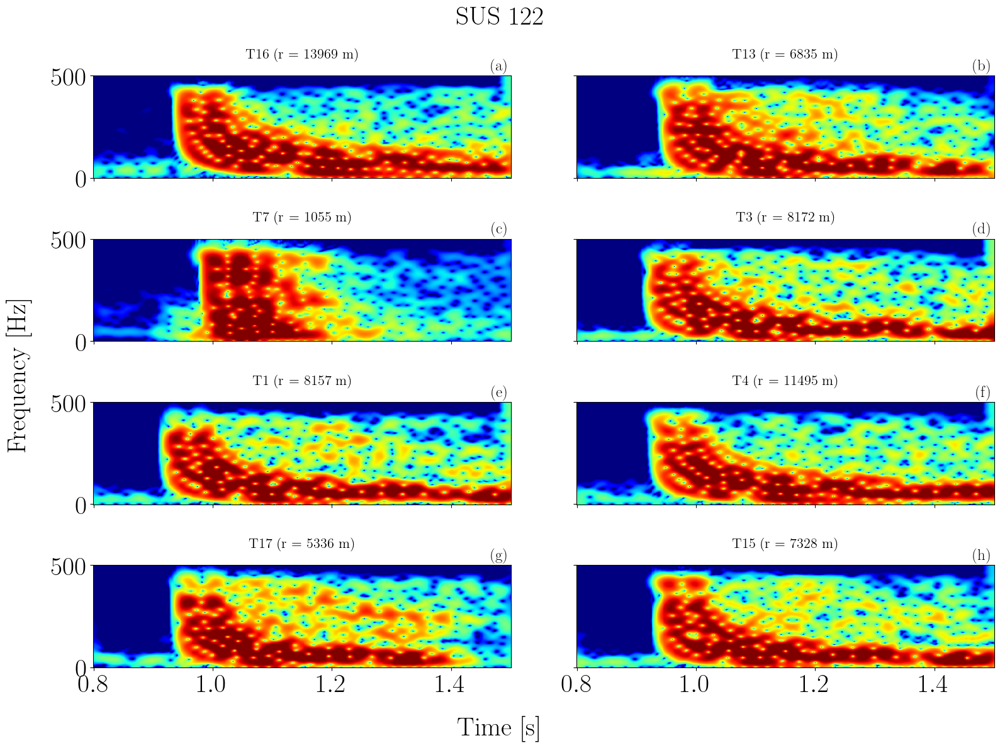

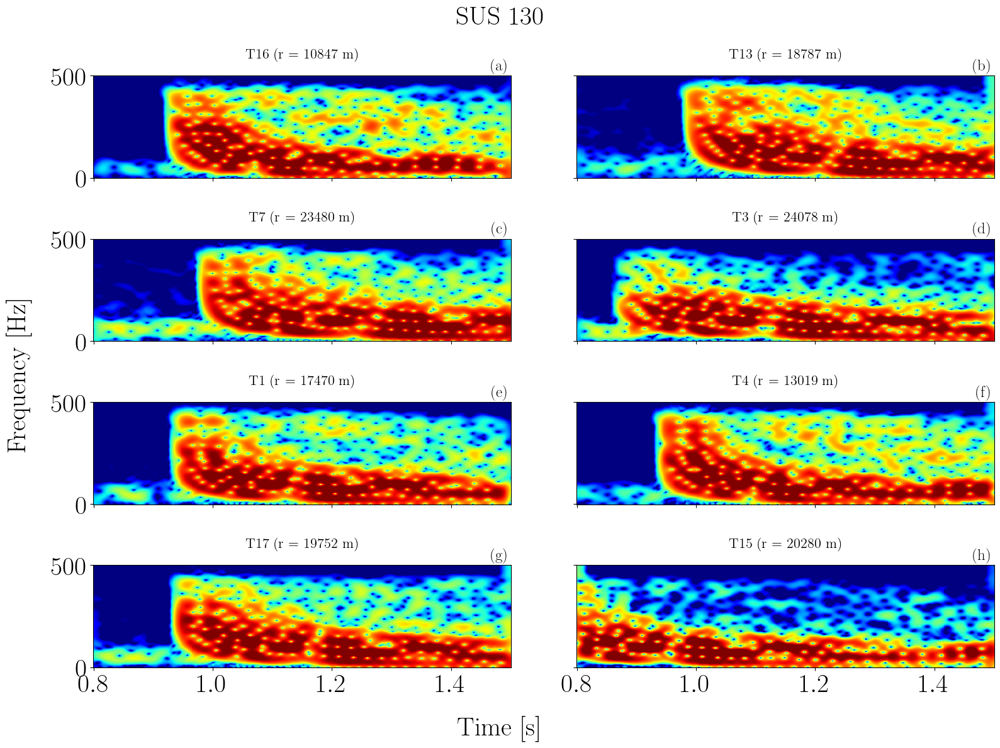

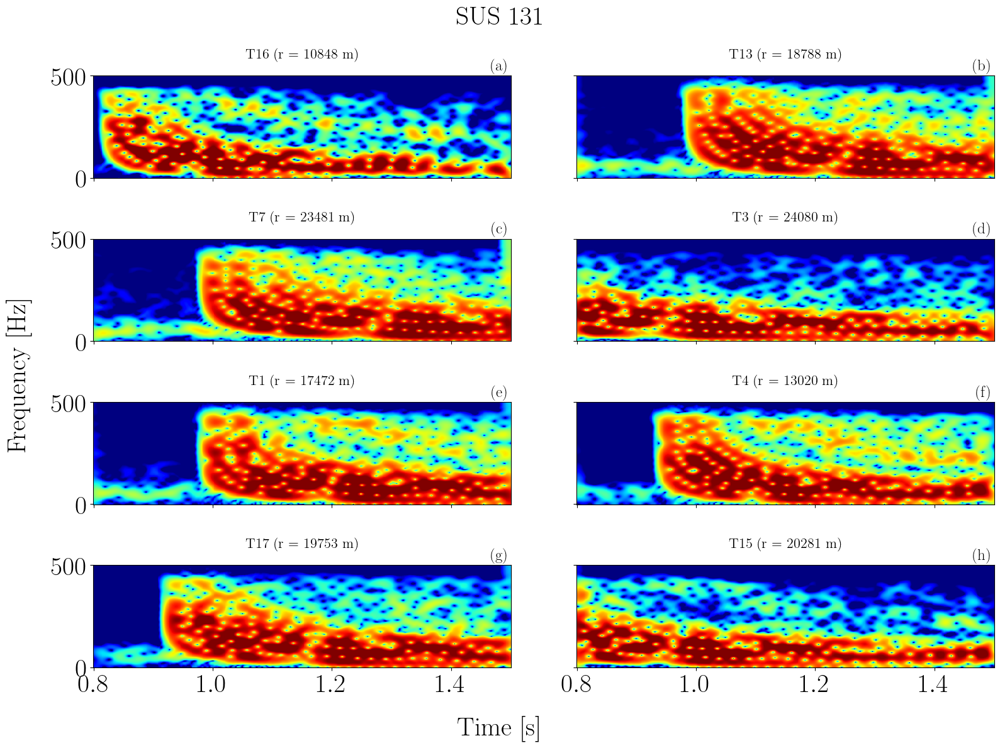

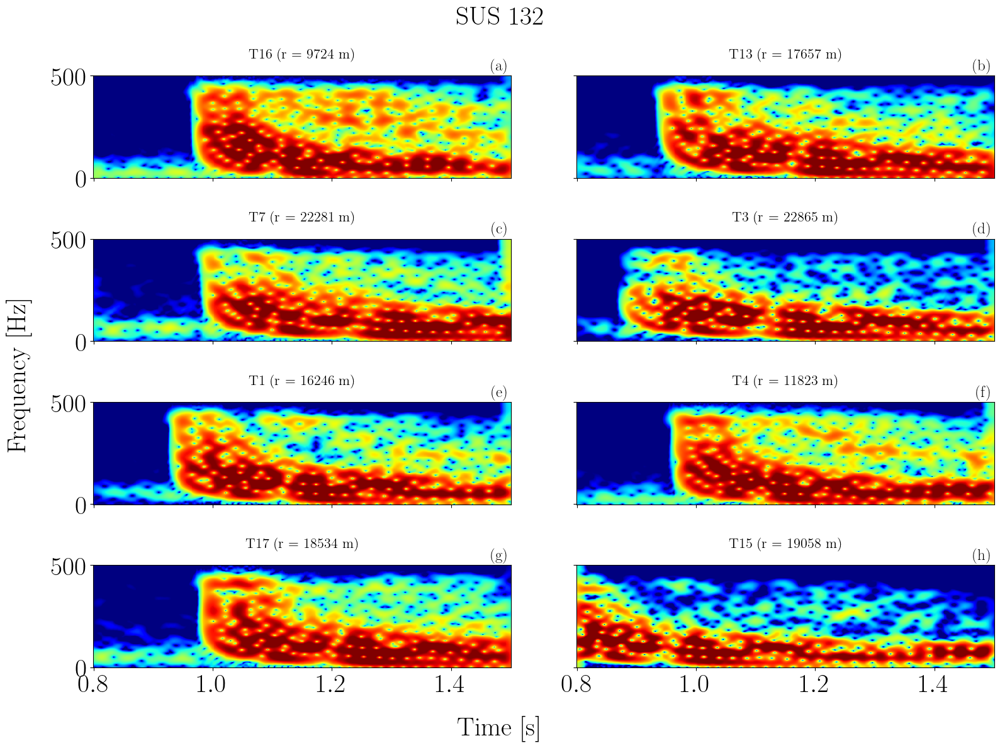

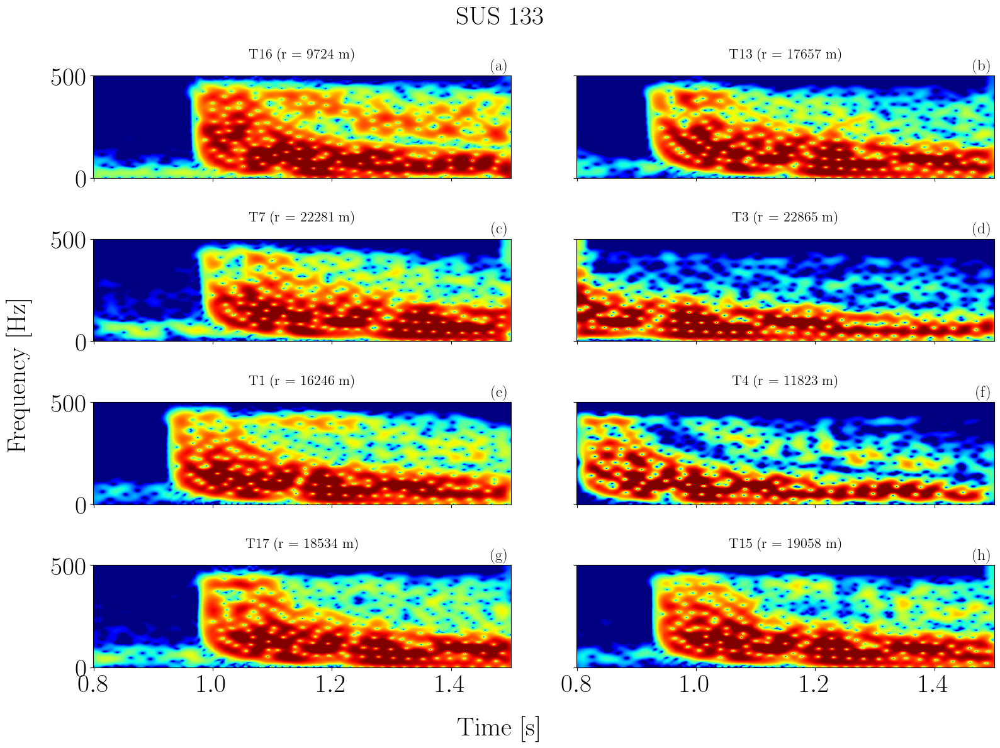

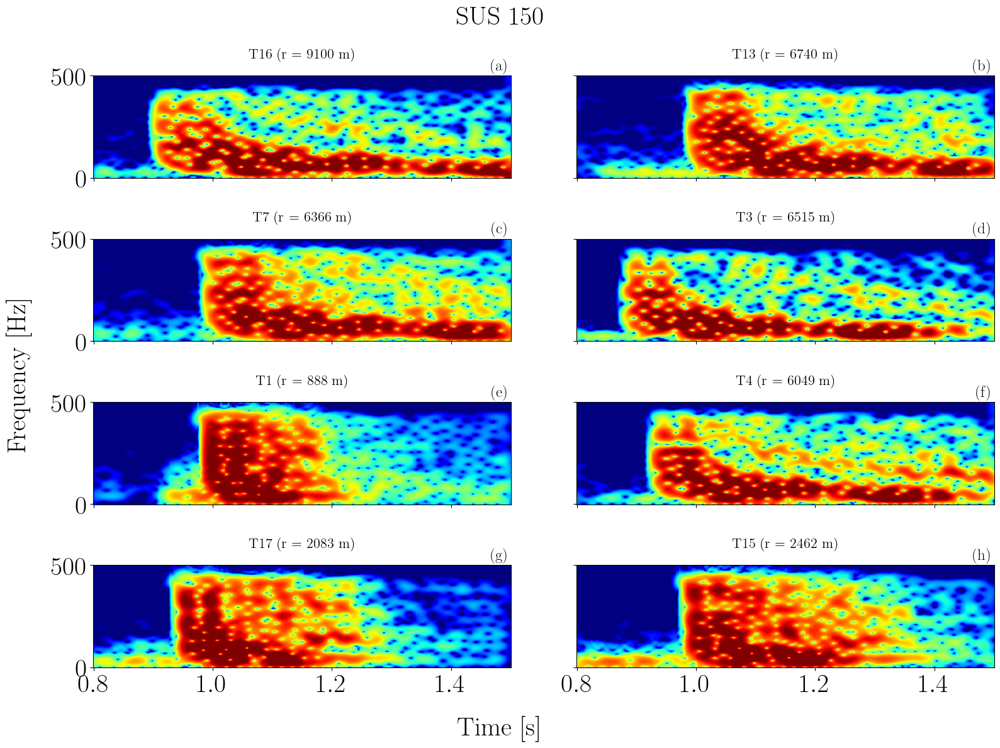

In [53]:
# Affichage des spectro pour chaque source
cmap = "jet"
decim_factor = 24  # decimate to 1 kHz
fs_new = fs / decim_factor

# Réglage identique au code du tuto de J.Bonnel 
nfft = 1024
nperseg = 51
noverlap = nperseg - 1
# noverlap = int(nperseg * 0.9)
print(f"nperseg = {nperseg}, noverlap = {noverlap}")

for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)
    # print(ds_sus_n)

    fig, axs = plt.subplots(
        nrows=len(tossit_n_visu) // 2,
        ncols=2,
        figsize=(16, 12),
        sharex=True,
        sharey=True,
    )
    # plt.figure(figsize=(12, 8))
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        sig_i = ds_tossit_n.s

        # Restrict to 0.8 s to 1.25 s
        t_start = 0.8
        t_end = 1.5
        sig_i = sig_i.sel(t=slice(t_start, t_end))
        sig_i = sig_i.values.flatten()

        # Decimate
        sig_i = sp.decimate(sig_i, decim_factor)  # decimate to 2 kHz

        # Derive stft
        ff, tt, stft = sp.stft(
            sig_i,
            fs=fs_new,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="psd",  # U^2 / Hz
            nfft=nfft,
        )
        sxx = 10 * np.log10(np.abs(stft))  # dB re 1uPa**2 / Hz 
        im = ax.pcolormesh(tt+t_start, ff, sxx, cmap=cmap, vmin=np.percentile(sxx, 20), vmax=np.percentile(sxx, 95))
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(
            f"T{tossit_n} (r = {ds_tossit_n.range.values[0]:.0f} m)", fontsize=16
        )

    fig.suptitle(f"SUS {sus_n}")
    fig.supxlabel("Time [s]")
    fig.supylabel("Frequency [Hz]")

    set_subfigures_abc_labels(
        axs=axs,
        fontsize=18,
        x_pos=0.995,
        y_pos=1.02,
        ha="right",
        va="bottom",
    )

    # plt.xlim(0.82, 1.25)
    # plt.ylim(0, 1000)

## Estimation des RTFs 

### Estimation pour des signaux non stationnaire 

On suppose le bruit négligeable : 

$$
X_1(f) = H_1(f) S(f) + V_1(f) \approx X_1(f) = H_1(f) S(f) 
$$

et

$$
X_2(f) = H_2(f) S(f) + V_2(f) \approx X_2(f) = H_2(f) S(f) 
$$

et le rapport des fonctions de transfert est estimé par : 


$$
\Pi(f) = \frac{S_{21}(f)}{S_{11}(f)}
$$

$$
\frac{S_{21}(f)}{S_{11}(f)} = \frac{ X_2(f) \overline{X_1}(f)}{\lvert X_1 (f) \rvert} \approx \frac{H_2(f) \overline{H_1}(f) \lvert S(f) \rvert^2}{\lvert H_1 (f) \rvert^2 \lvert S(f) \rvert^2} = \frac{H_{2}(f)}{H_{1}(f)}
$$

In [54]:
tossit_ref = 1      # TOSSIT T1 as reference 

In [55]:
# Compute RTF
nfft = 2**16
f_fft = np.fft.rfftfreq(nfft, d=1 / fs)

pi = []

for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)

    pi_sus_n = []

    idx_tossit_ref = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_ref]
    ds_tossit_ref = ds_sus_n.sel(id=idx_tossit_ref)
    sig_ref = ds_tossit_ref.s.values.flatten()
    fft_tossit_ref = np.fft.rfft(sig_ref, n=nfft)
    syy = fft_tossit_ref * np.conj(fft_tossit_ref)

    # Iterate over all tossits and compute RTF
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        sig_i = ds_tossit_n.s
        sig_i = sig_i.values.flatten()

        fft_tossit_i = np.fft.rfft(sig_i, n=nfft)
        sxy = fft_tossit_i * np.conj(fft_tossit_ref)

        # TOSSIT i / TOSSIT ref
        pi_iref = sxy / syy

        # Store 
        pi_sus_n.append(pi_iref)

    pi_sus_n = np.array(pi_sus_n)

    pi.append(pi_sus_n)

pi = np.array(pi)
print(pi.shape)
    

(7, 8, 32769)


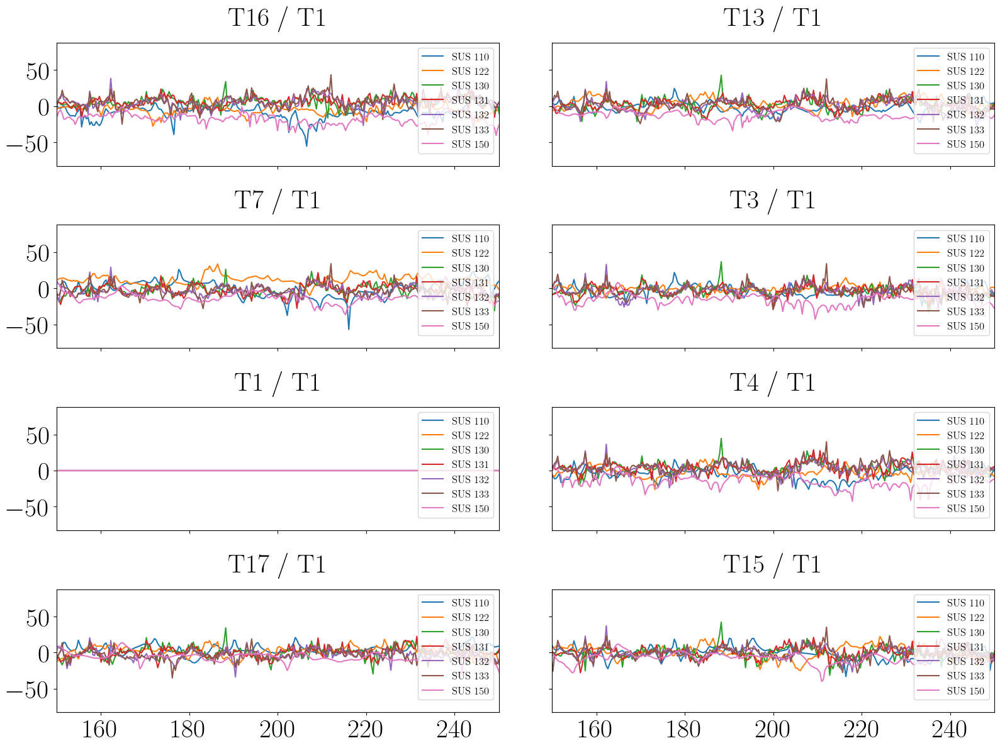

In [58]:
fig, axs = plt.subplots(
    nrows=len(tossit_n_visu) // 2,
    ncols=2,
    figsize=(16, 12),
    sharex=True,
    sharey=True,
)


for i_sus, sus_n_x in enumerate(sus_n_visu):

    # Iterate over all tossits and compute RTF
    for i_tossit, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_tossit]

        pi_iref = pi[i_sus, i_tossit, :]
        ax.plot(f_fft, 20 * np.log10(np.abs(pi_iref)), label=f"SUS {sus_n_x}")

plt.xlim(150, 250)

for i_tossit, tossit_n in enumerate(tossit_n_visu):
    ax = axs.flat[i_tossit]
    ax.set_title(f"T{tossit_n} / T{tossit_ref}")
    ax.legend(fontsize=12)

# Signaux émis depuis des positions similaires

In [79]:
sus_n_visu = [130, 131, 132, 133, 134, 135, 136, 137]
idx_to_keep = np.array([ds_sig.id.values[ds_sig.sus_n == sus_n] for sus_n in sus_n_visu]).flatten()
# print(idx_to_keep)
ds_visu = ds_sig.sel(id=idx_to_keep)
ds_visu

<xarray.Dataset> Size: 105MB
Dimensions:   (t: 96001, id: 136)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 544B 24 121 218 315 412 ... 1195 1292 1389 1486 1583
Data variables:
    s         (t, id) float64 104MB -1.002 1.522 0.5816 ... 0.685 -0.1399
    range     (id) float64 1kB 1.747e+04 2.275e+04 ... 1.599e+04 1.137e+04
    sus_n     (id) uint8 136B 130 130 130 130 130 130 ... 137 137 137 137 137
    tossit_n  (id) uint8 136B 1 2 3 4 5 6 7 9 10 ... 10 11 12 13 14 15 16 17 18

In [80]:
src_pos_visu = src_pos.loc[sus_n_visu]
src_pos_visu

,lon,lat,time_num,time_str,datetime
id,,,,,
130,-70.772667,40.459017,739753.902799,16-May-2025 21:40:01,2025-05-16 21:40:01
131,-70.772683,40.459033,739753.903454,16-May-2025 21:40:58,2025-05-16 21:40:58
132,-70.758233,40.459000,739753.914896,16-May-2025 21:57:26,2025-05-16 21:57:26
133,-70.758233,40.459000,739753.915479,16-May-2025 21:58:17,2025-05-16 21:58:17
134,-70.742733,40.459433,739753.927286,16-May-2025 22:15:17,2025-05-16 22:15:17
135,-70.742717,40.459433,739753.927877,16-May-2025 22:16:08,2025-05-16 22:16:08
136,-70.728117,40.459267,739753.938435,16-May-2025 22:31:20,2025-05-16 22:31:20
137,-70.728133,40.459267,739753.939050,16-May-2025 22:32:13,2025-05-16 22:32:13


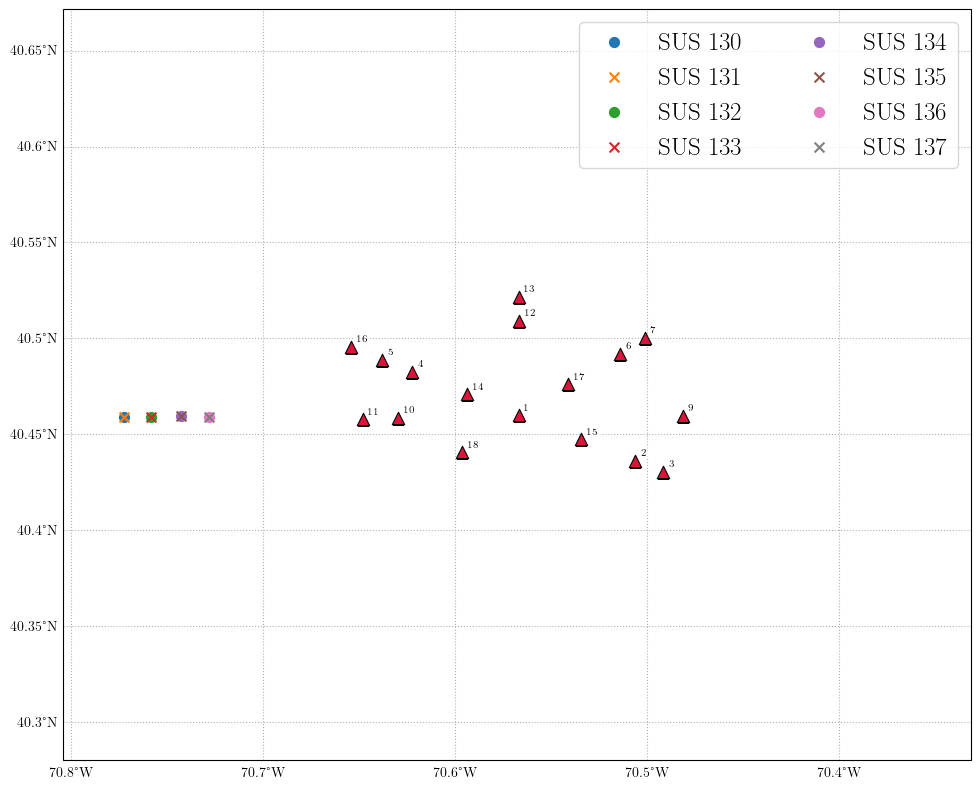

In [81]:
# Plot source position for selected ranges
pad = 0.15  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


z = bathy_zoom["elevation"].values
lon = bathy_zoom["lon"].values
lat = bathy_zoom["lat"].values

# # Hillshade
# ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
# rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )

# Zoom on the area of interest
ax.set_extent(zoom_extent)

# Source positions
for sus_n in sus_n_visu:
    src_i = src_pos.loc[sus_n]
    marker = "o" if sus_n%2 == 0 else "x"
    ax.scatter(src_i.lon, src_i.lat, marker=marker, s=50, label=f"SUS {sus_n}")

# sc = ax.scatter(src_pos_visu.lon, src_pos_visu.lat, , marker="x", s=12)
# plt.colorbar(sc)
# plt.tight_layout()

plt.legend(fontsize=18, ncol=2)

# plt.show()
# plt.xlim(70.8, 70.7)

In [82]:
# Choix des récepteurs à visualiser
tossit_n_visu = [16, 13, 7, 3, 1, 4, 17, 15]
idx_to_keep = np.array(
    [ds_visu.id.values[ds_visu.tossit_n == tossit_n] for tossit_n in tossit_n_visu]
).flatten()
ds_visu = ds_visu.sel(id=idx_to_keep)
ds_visu

<xarray.Dataset> Size: 50MB
Dimensions:   (t: 96001, id: 64)
Coordinates:
  * t         (t) float64 768kB 0.0 4.167e-05 8.333e-05 0.000125 ... 4.0 4.0 4.0
  * id        (id) int32 256B 1382 1383 1384 1385 1386 ... 1289 1290 1291 1292
Data variables:
    s         (t, id) float64 49MB 1.063 -0.1968 -0.025 ... -0.9143 0.8022
    range     (id) float64 512B 1.085e+04 1.085e+04 ... 1.651e+04 1.651e+04
    sus_n     (id) uint8 64B 130 131 132 133 134 135 ... 132 133 134 135 136 137
    tossit_n  (id) uint8 64B 16 16 16 16 16 16 16 16 ... 15 15 15 15 15 15 15 15

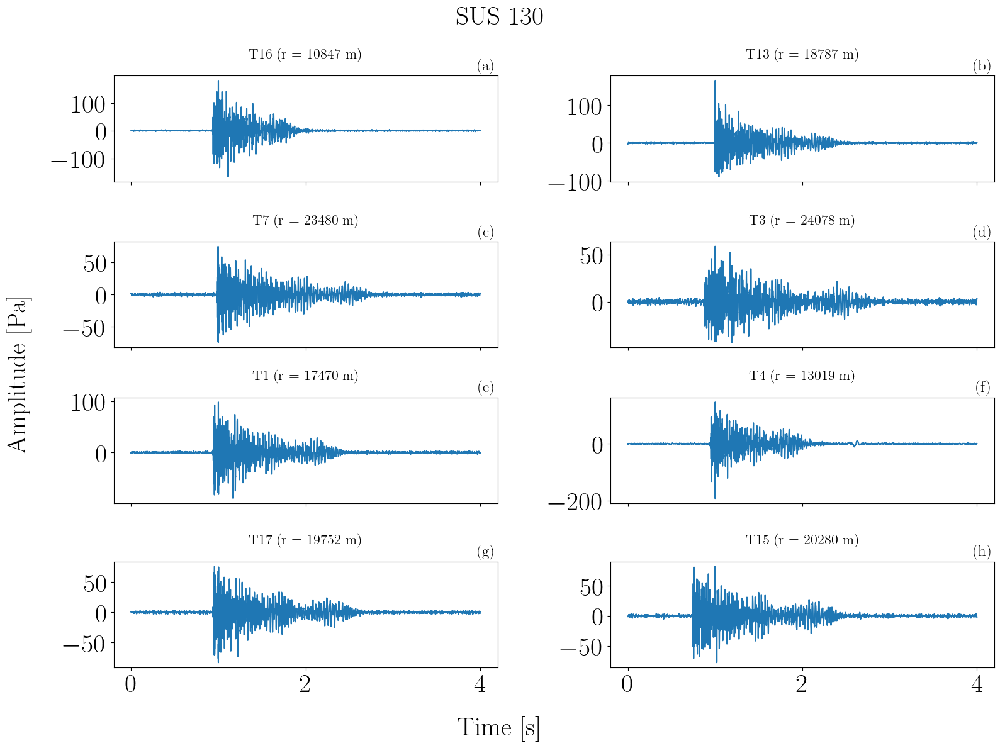

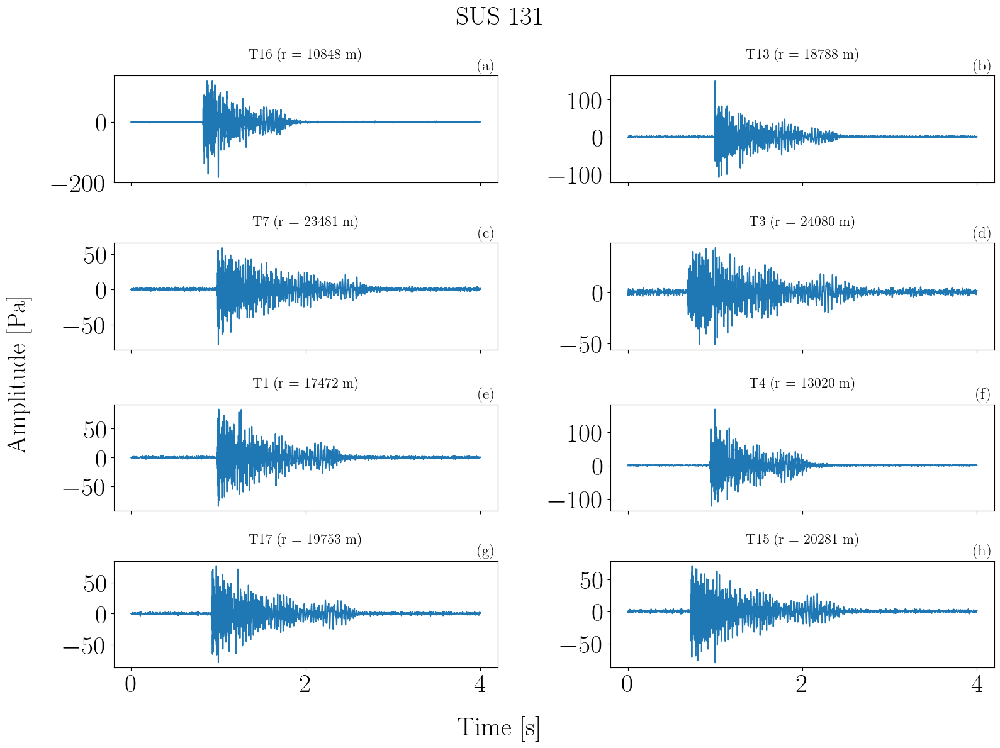

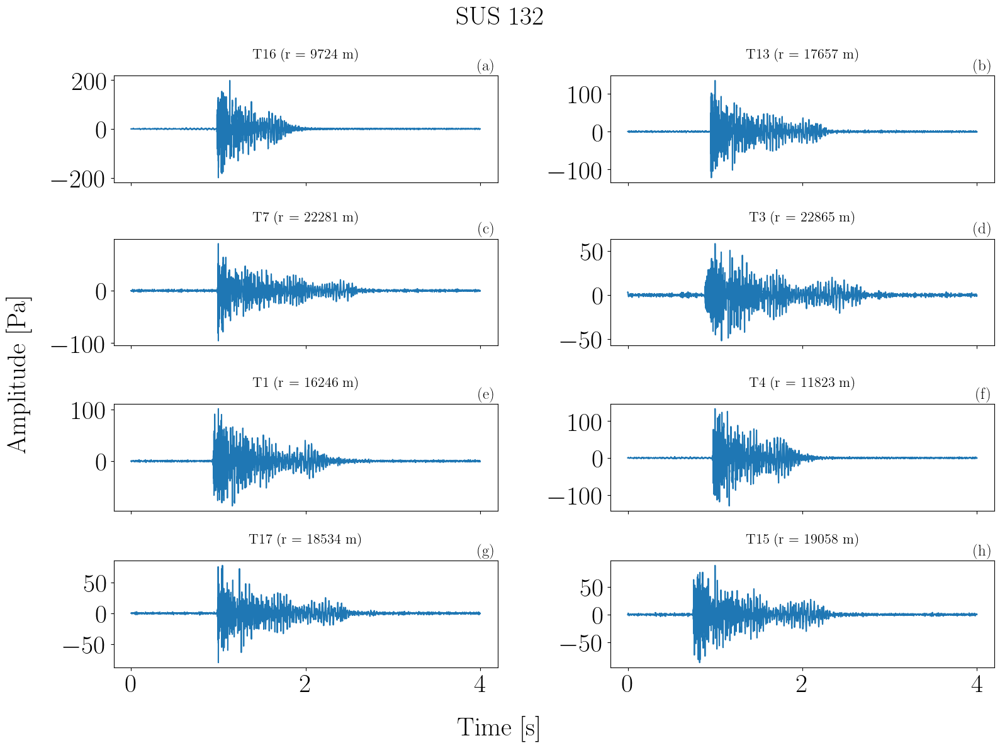

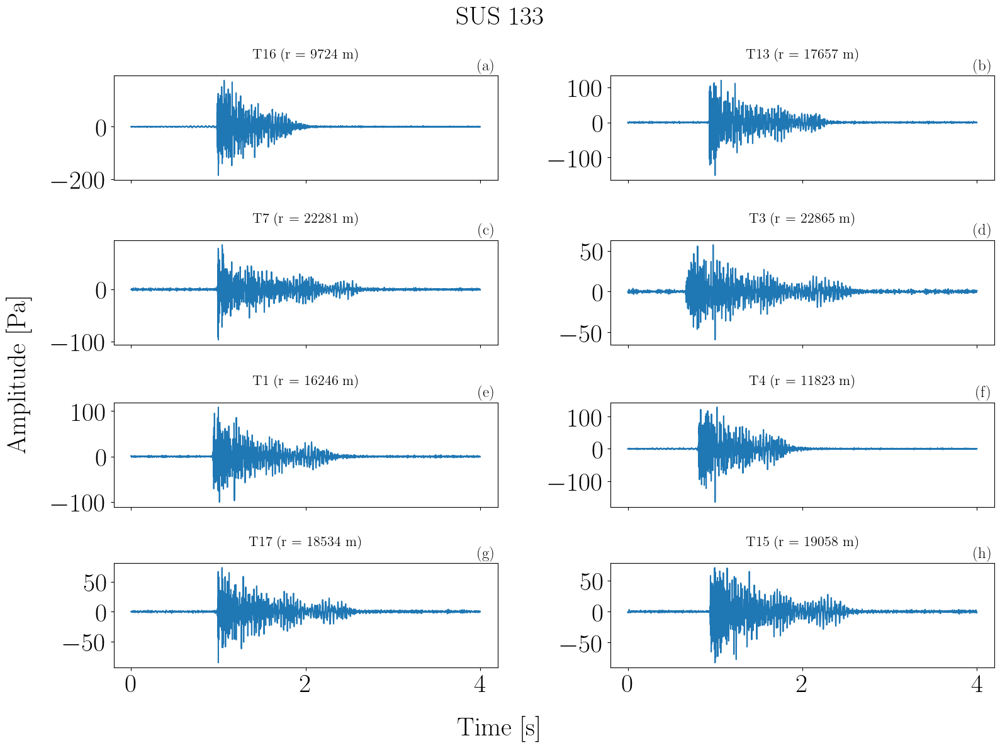

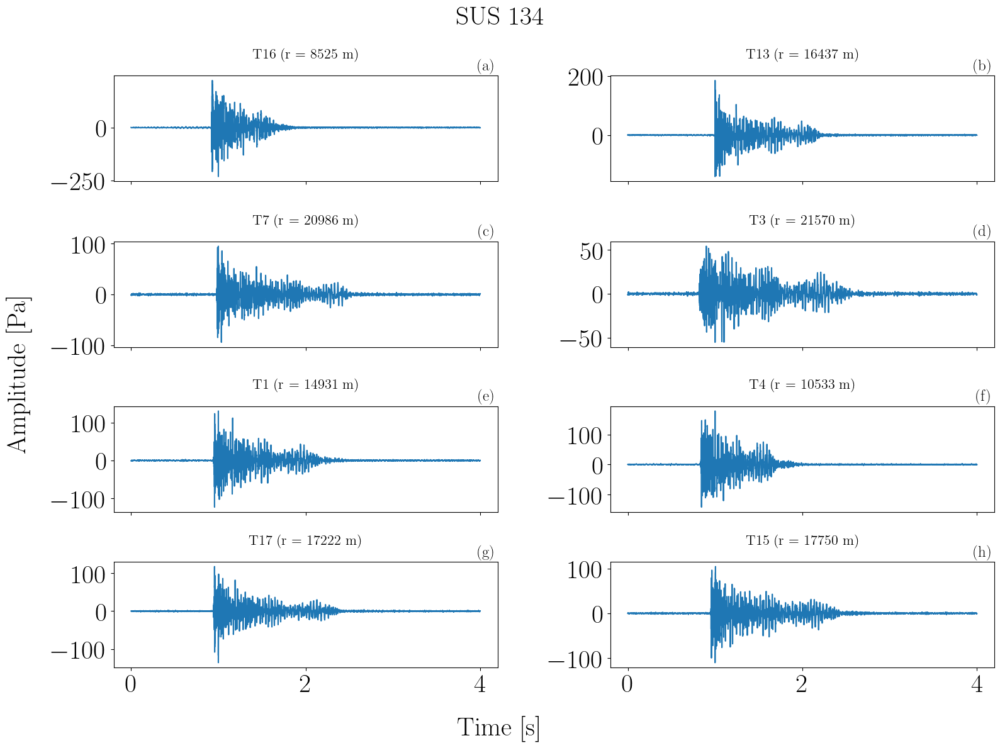

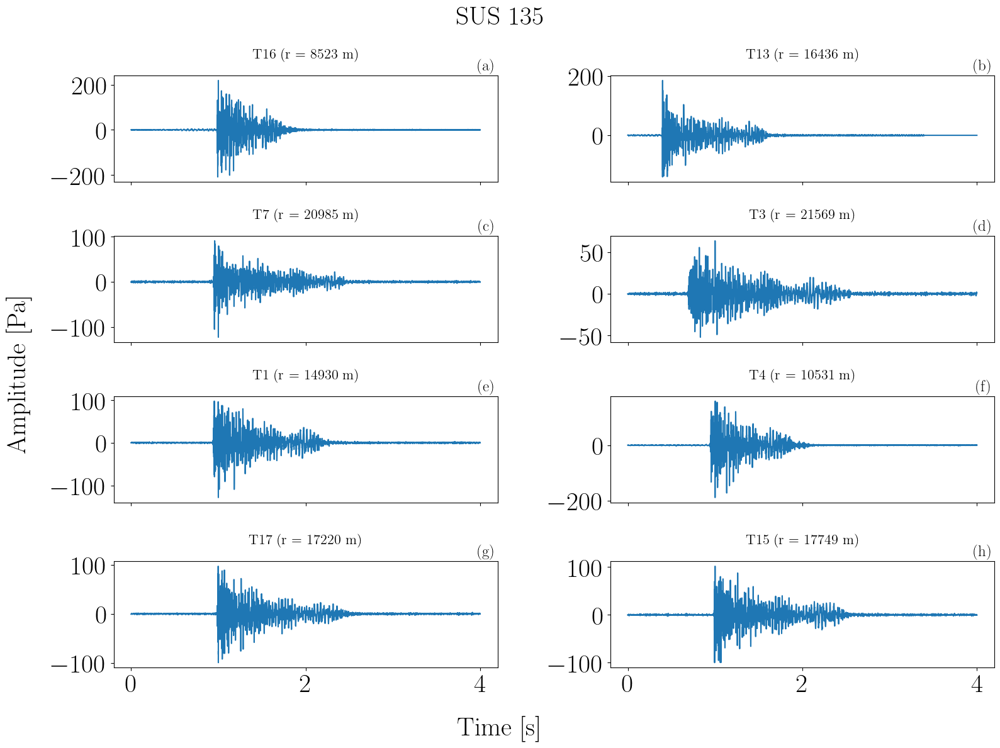

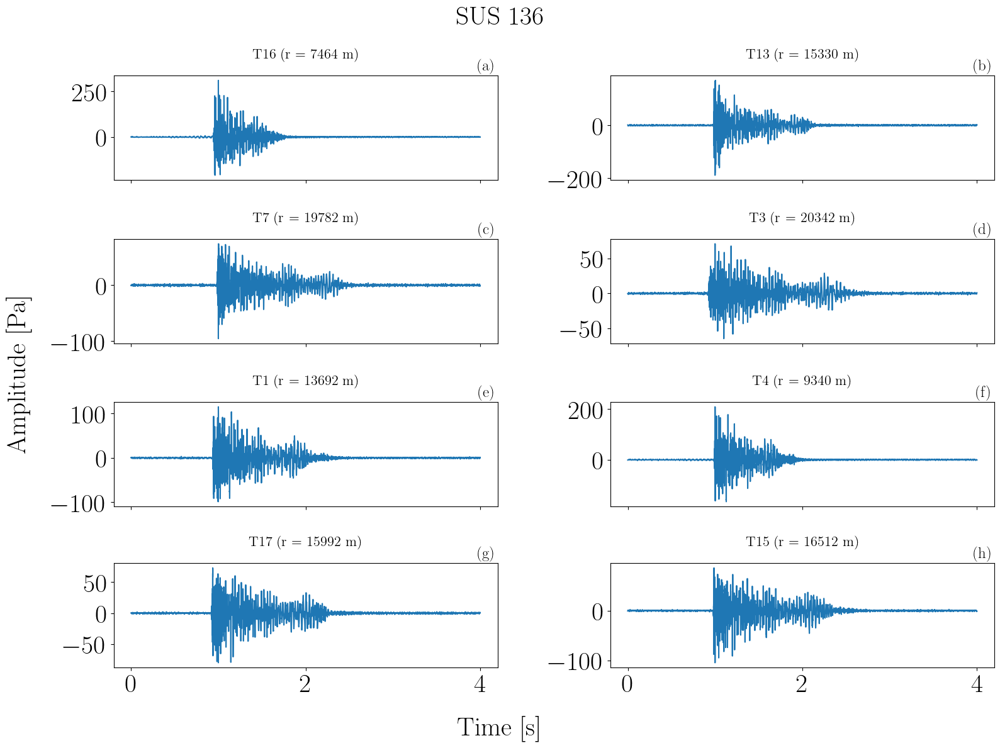

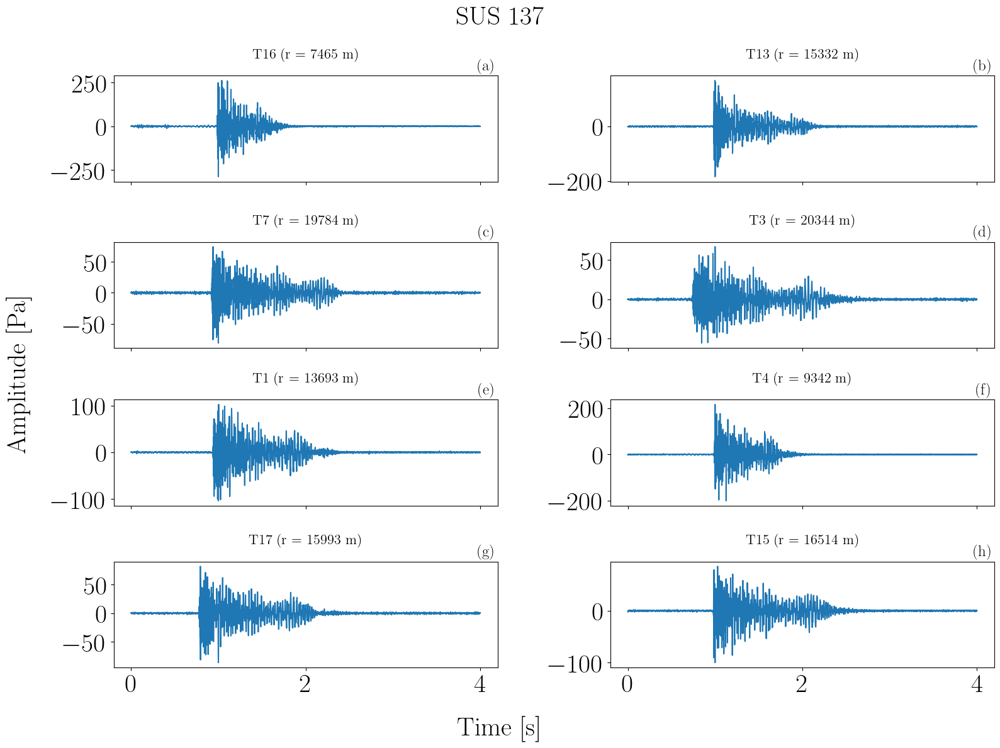

In [83]:
# Affichage des signaux pour chaque source
for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)
    # print(ds_sus_n)

    fig, axs = plt.subplots(
        nrows=len(tossit_n_visu) // 2,
        ncols=2,
        figsize=(16, 12),
        sharex=True,
        sharey=False,
    )
    # plt.figure(figsize=(12, 8))
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        ds_tossit_n.s.plot(ax=ax, label=f"T{tossit_n}")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(f"T{tossit_n} (r = {ds_tossit_n.range.values[0]:.0f} m)", fontsize=16)

    fig.suptitle(f"SUS {sus_n}")
    fig.supxlabel("Time [s]")
    fig.supylabel("Amplitude [Pa]")

    set_subfigures_abc_labels(
        axs=axs,
        fontsize=18,
        x_pos=0.995,
        y_pos=1.02,
        ha="right",
        va="bottom",
    )

nperseg = 51, noverlap = 50


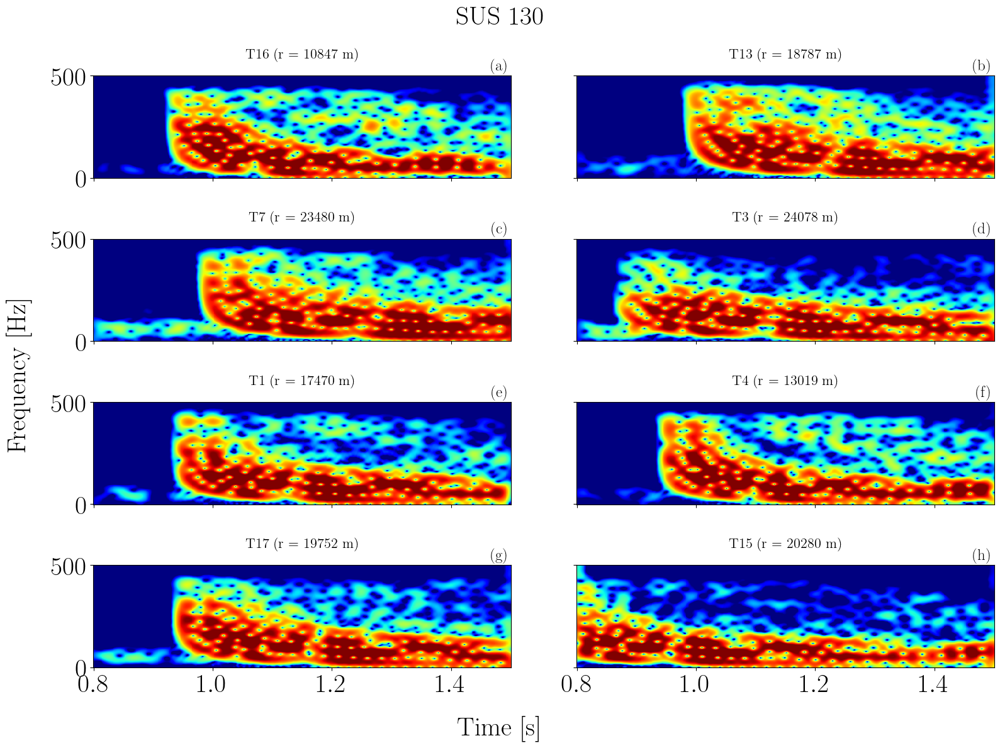

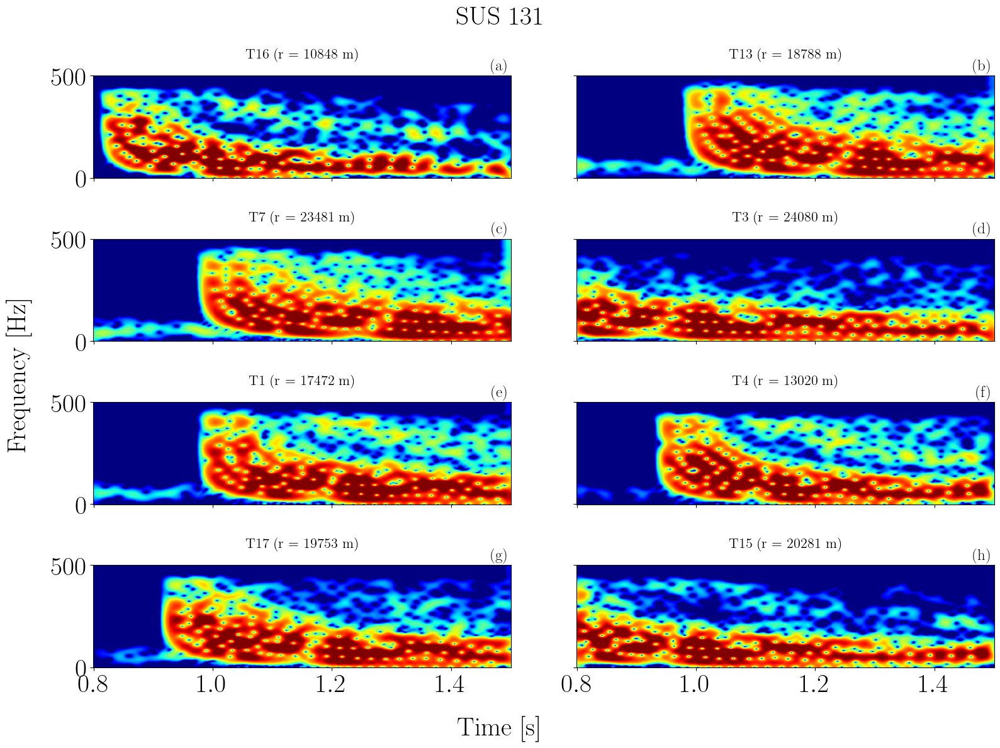

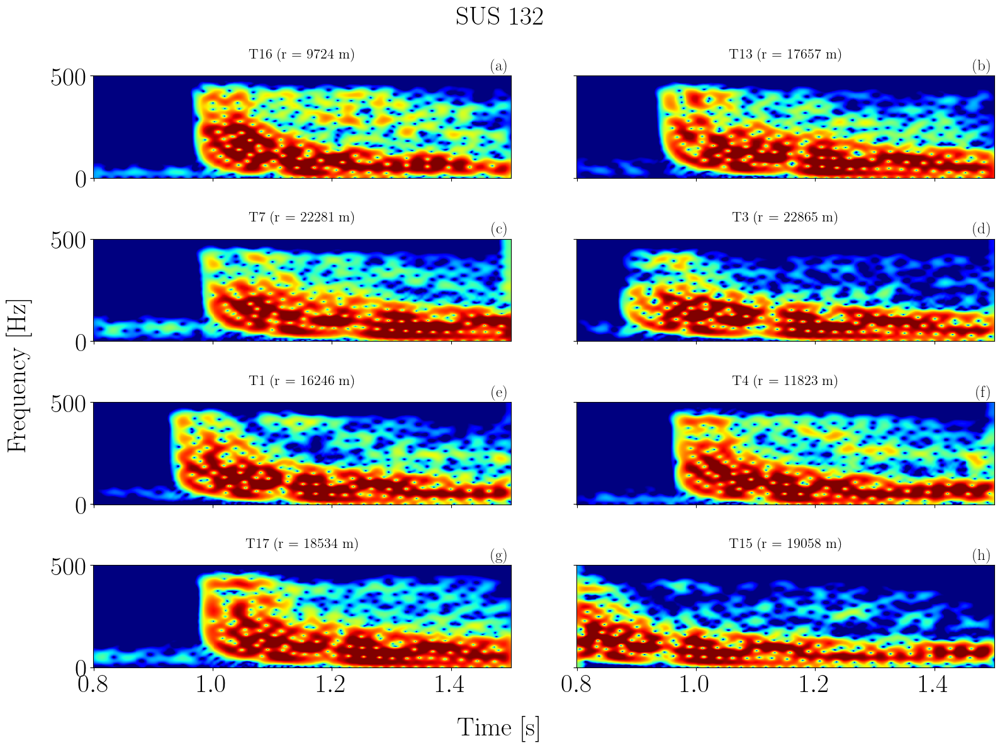

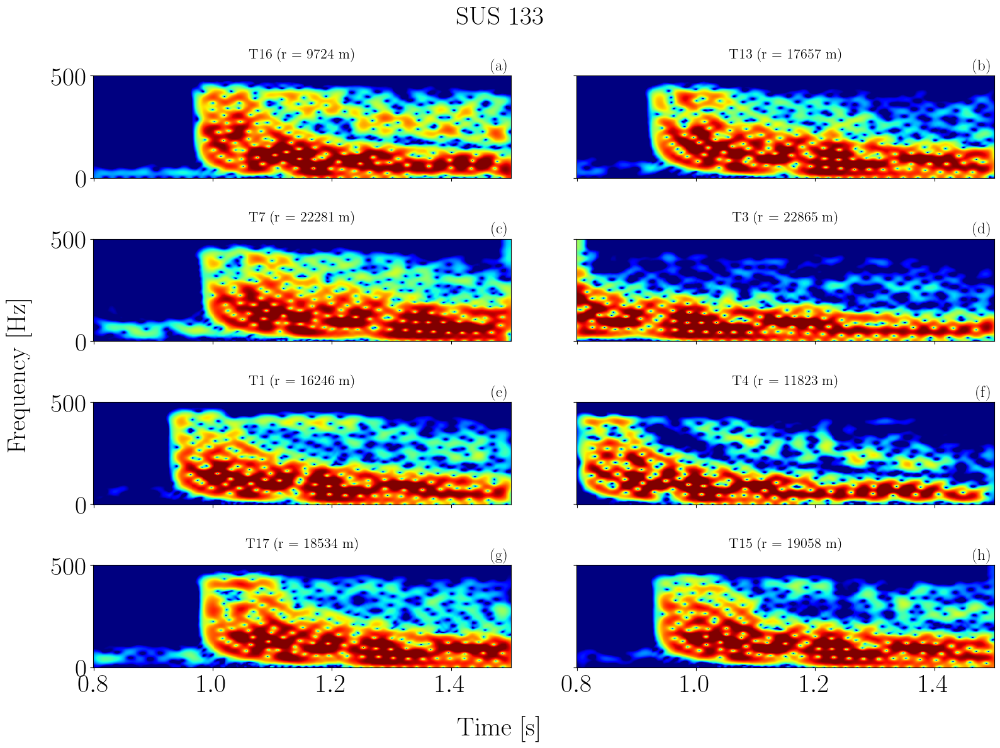

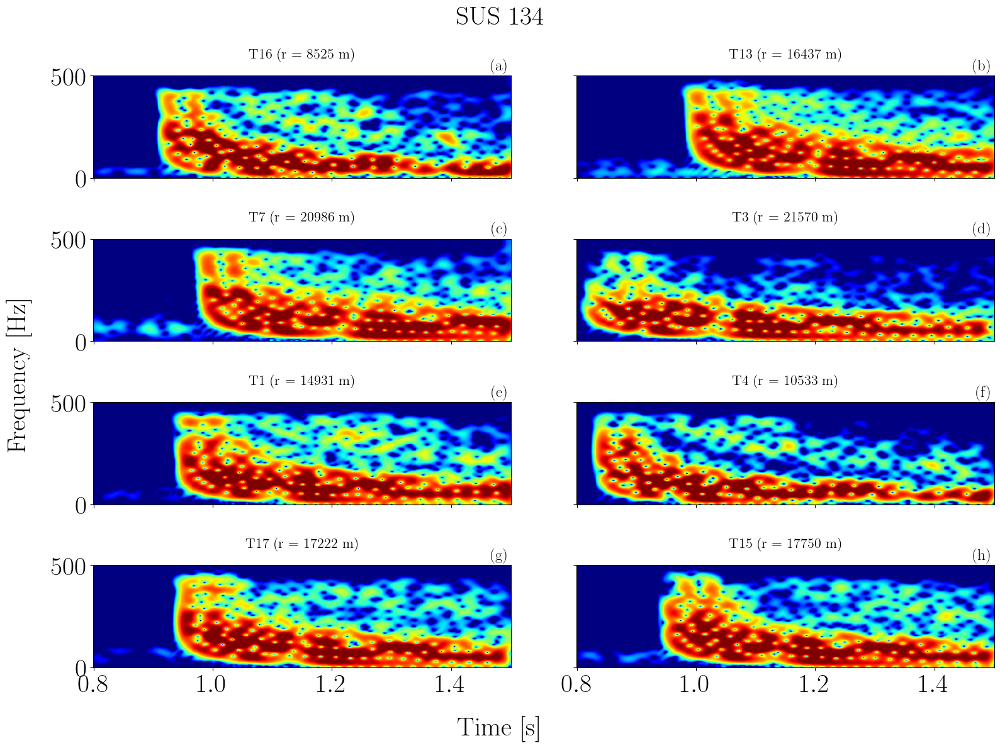

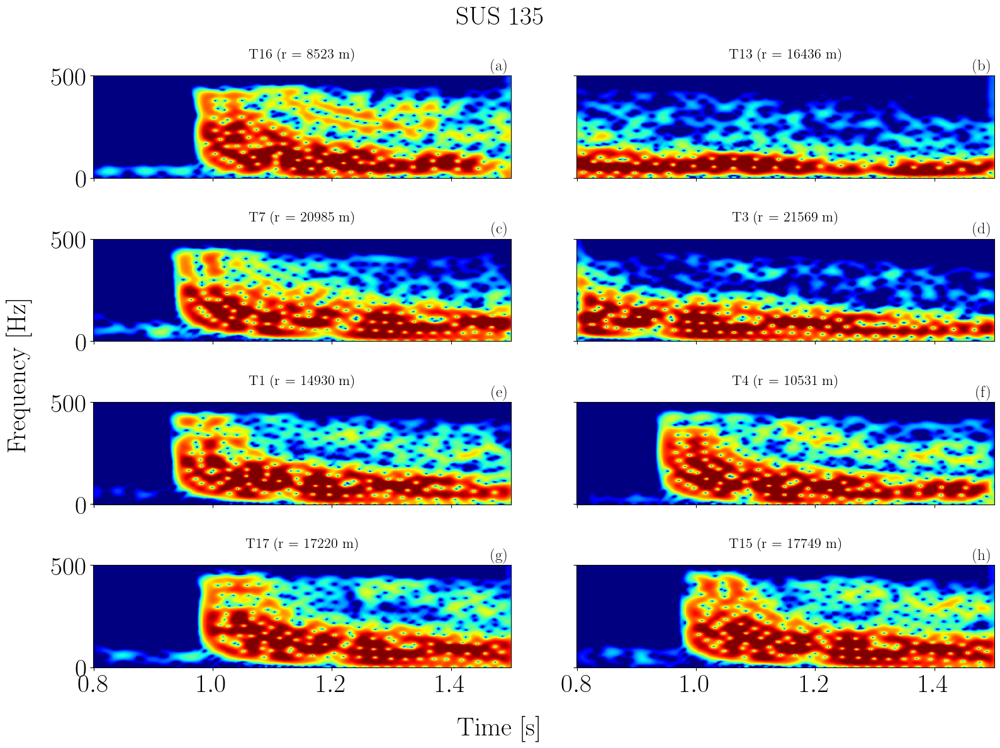

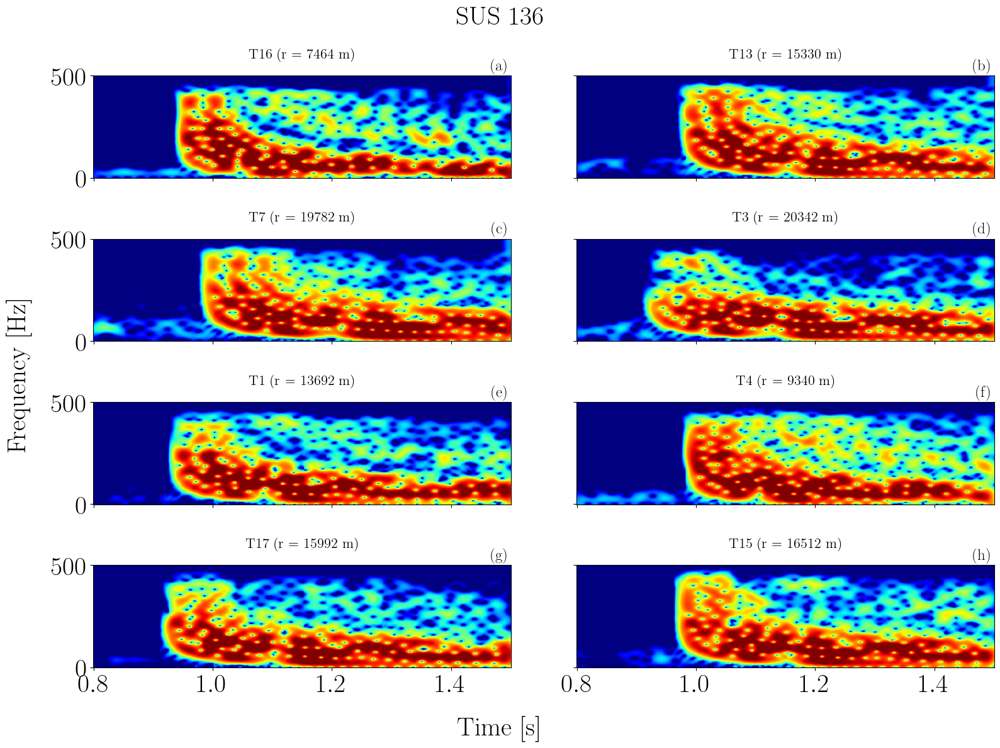

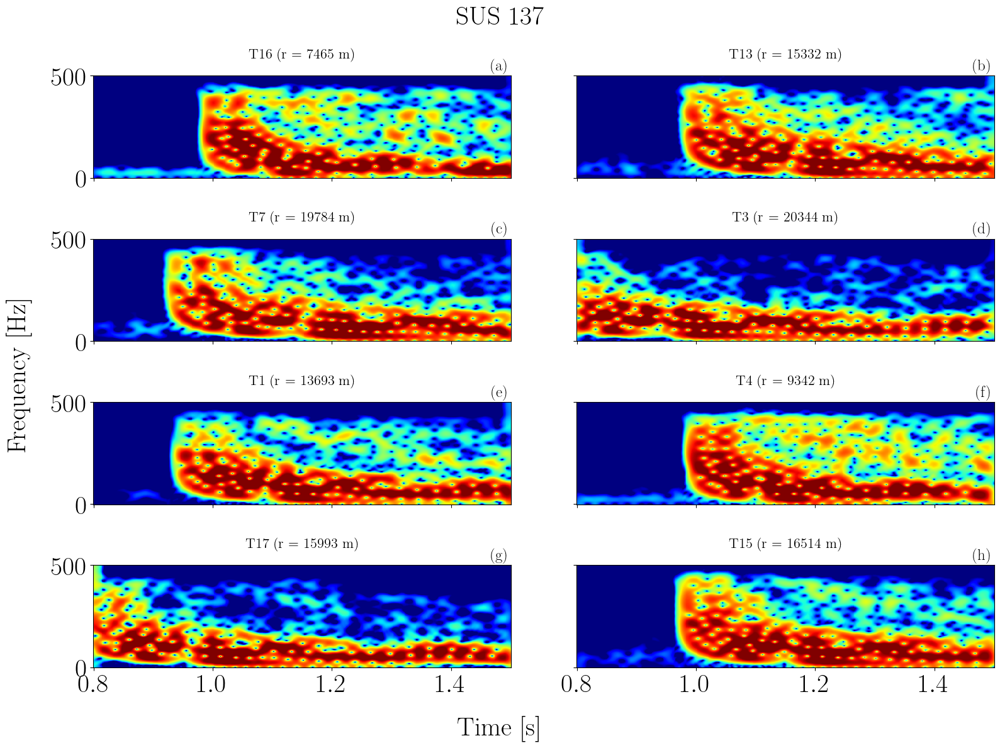

In [127]:
# Affichage des spectro pour chaque source
cmap = "jet"
decim_factor = 24  # decimate to 1 kHz
fs_new = fs / decim_factor

# Réglage identique au code du tuto de J.Bonnel 
nfft = 1024
nperseg = 51
noverlap = nperseg - 1
# noverlap = int(nperseg * 0.9)
print(f"nperseg = {nperseg}, noverlap = {noverlap}")

for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)
    # print(ds_sus_n)

    fig, axs = plt.subplots(
        nrows=len(tossit_n_visu) // 2,
        ncols=2,
        figsize=(16, 12),
        sharex=True,
        sharey=True,
    )
    # plt.figure(figsize=(12, 8))
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        sig_i = ds_tossit_n.s

        # Restrict to 0.8 s to 1.25 s
        t_start = 0.8
        t_end = 1.5
        sig_i = sig_i.sel(t=slice(t_start, t_end))
        sig_i = sig_i.values.flatten()

        # Decimate
        sig_i = sp.decimate(sig_i, decim_factor)  # decimate to 2 kHz

        # Derive stft
        ff, tt, stft = sp.stft(
            sig_i,
            fs=fs_new,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="psd",  # U^2 / Hz
            nfft=nfft,
        )
        sxx = 10 * np.log10(np.abs(stft))  # dB re 1uPa**2 / Hz 
        im = ax.pcolormesh(tt+t_start, ff, sxx, cmap=cmap, vmin=np.percentile(sxx, 30), vmax=np.percentile(sxx, 95))
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(
            f"T{tossit_n} (r = {ds_tossit_n.range.values[0]:.0f} m)", fontsize=16
        )

    fig.suptitle(f"SUS {sus_n}")
    fig.supxlabel("Time [s]")
    fig.supylabel("Frequency [Hz]")

    set_subfigures_abc_labels(
        axs=axs,
        fontsize=18,
        x_pos=0.995,
        y_pos=1.02,
        ha="right",
        va="bottom",
    )

    # plt.xlim(0.82, 1.25)
    # plt.ylim(0, 1000)

In [85]:
tossit_ref = 1      # TOSSIT T1 as reference 

In [86]:
# Compute RTF
nfft = 2**18
f_fft = np.fft.rfftfreq(nfft, d=1 / fs)

pi = []

for sus_n in sus_n_visu:
    idx_sus_n = ds_visu.id.values[ds_visu.sus_n == sus_n]
    ds_sus_n = ds_visu.sel(id=idx_sus_n)

    pi_sus_n = []

    idx_tossit_ref = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_ref]
    ds_tossit_ref = ds_sus_n.sel(id=idx_tossit_ref)
    sig_ref = ds_tossit_ref.s.values.flatten()
    fft_tossit_ref = np.fft.rfft(sig_ref, n=nfft)
    syy = fft_tossit_ref * np.conj(fft_tossit_ref)

    # Iterate over all tossits and compute RTF
    for i_ax, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_ax]
        idx_tossit_n = ds_sus_n.id.values[ds_sus_n.tossit_n == tossit_n]
        ds_tossit_n = ds_sus_n.sel(id=idx_tossit_n)
        sig_i = ds_tossit_n.s
        sig_i = sig_i.values.flatten()

        fft_tossit_i = np.fft.rfft(sig_i, n=nfft)
        sxy = fft_tossit_i * np.conj(fft_tossit_ref)

        # TOSSIT i / TOSSIT ref
        pi_iref = sxy / syy

        # Store 
        pi_sus_n.append(pi_iref)

    pi_sus_n = np.array(pi_sus_n)

    pi.append(pi_sus_n)

pi = np.array(pi)
print(pi.shape)
    

(8, 8, 131073)


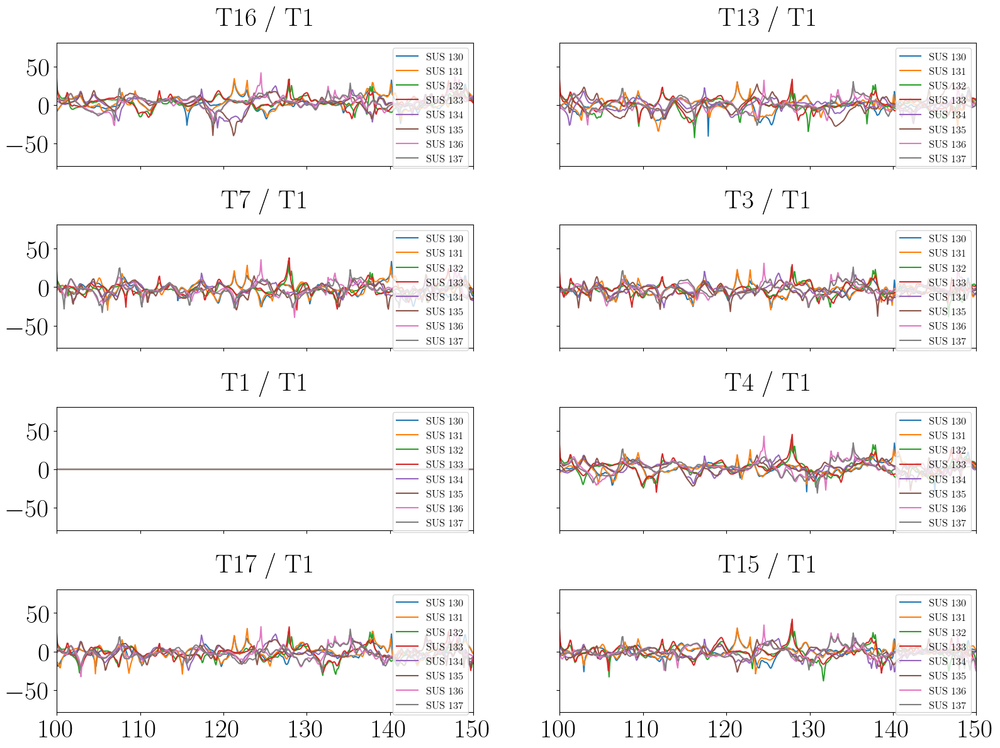

In [93]:
fig, axs = plt.subplots(
    nrows=len(tossit_n_visu) // 2,
    ncols=2,
    figsize=(16, 12),
    sharex=True,
    sharey=True,
)


for i_sus, sus_n in enumerate(sus_n_visu):

    # Iterate over all tossits and compute RTF
    for i_tossit, tossit_n in enumerate(tossit_n_visu):
        ax = axs.flat[i_tossit]

        pi_iref = pi[i_sus, i_tossit, :]
        ax.plot(f_fft, 20 * np.log10(np.abs(pi_iref)), label=f"SUS {sus_n}")

plt.xlim(100, 150)

for i_tossit, tossit_n in enumerate(tossit_n_visu):
    ax = axs.flat[i_tossit]
    ax.set_title(f"T{tossit_n} / T{tossit_ref}")
    ax.legend(fontsize=12)
    # ax.set_ylim(-30,30)

Les paires d'émissions correspondant à des positions similaires coïncident. Les variations minimes de positions conduisent néanmoins à des légères variations visibles.   


Question : quel système / précision pour le positionnement ? 

In [119]:
# Calcul de distance entre chaque RTF et le reste des RTFs

distance = {tossit_n: [] for tossit_n in tossit_n_visu}

for i_tossit, tossit_n in enumerate(tossit_n_visu):
    distance[tossit_n] = np.zeros((len(sus_n_visu), len(sus_n_visu)))

    for i_sus1, sus_n1 in enumerate(sus_n_visu):

        rtf_1 = pi[i_sus1, :, :]
        for i_sus2, sus_n2 in enumerate(sus_n_visu):
            rtf_2 = pi[i_sus2, :, :]

            dist_12 = []
            # print(f"SUS {sus_n1} vs SUS {sus_n2}: TOSSIT {tossit_n}")

            # Angle theta
            # # rtf_1_tossit = 20 * np.log10(np.abs(rtf_1[i_tossit, :]))
            # # rtf_2_tossit = 20 * np.log10(np.abs(rtf_2[i_tossit, :]))
            # # rtf_1_tossit = np.abs(rtf_1[i_tossit, :])
            # # rtf_2_tossit = np.abs(rtf_2[i_tossit, :])
            # rtf_1_tossit = rtf_1[i_tossit, :]
            # rtf_2_tossit = rtf_2[i_tossit, :]

            # # Calculate inner product and norms along the receiver axis
            # # inner_prod = np.sum(rtf_1_tossit * rtf_2_tossit)
            # # inner_prod = np.abs(np.sum(rtf_1_tossit * rtf_2_tossit))

            # norm_1 = np.linalg.norm(rtf_1_tossit)
            # norm_2 = np.linalg.norm(rtf_2_tossit)

            # # Calculate cosine of Hermitian angle, clipped to [-1, 1] for stability
            # cos_angle = np.clip(inner_prod / (norm_1 * norm_2), -1.0, 1.0)
            # dist = np.arccos(cos_angle)
            # print(f"Angle (rad): {dist:.4f}, Angle (deg): {np.degrees(dist):.2f}")

            # Norme L1
            rtf_1_tossit = 20 * np.log10(np.abs(rtf_1[i_tossit, :]))
            rtf_2_tossit = 20 * np.log10(np.abs(rtf_2[i_tossit, :]))   
            d_L2 = np.sqrt(np.sum((rtf_1_tossit - rtf_2_tossit) ** 2))
            dist = d_L2
            # print(f"Norme L2 : {dist:.4f}")

            distance[tossit_n][i_sus1, i_sus2] = dist

        # Replace the diagonal with NaN for better visualization
        distance[tossit_n][np.diag_indices_from(distance[tossit_n])] = np.nan

In [120]:
distance

{16: array([[          nan, 3637.3361535 , 4508.26761377, 4429.02533457,
         4344.27525183, 4207.1598999 , 4446.68266839, 4573.81993843],
        [3637.3361535 ,           nan, 4418.37659123, 4174.0793213 ,
         4351.36145522, 4259.00002261, 4205.70159166, 4502.65778614],
        [4508.26761377, 4418.37659123,           nan, 3940.0780071 ,
         4104.59229206, 4032.38996169, 4286.27695955, 4305.90455151],
        [4429.02533457, 4174.0793213 , 3940.0780071 ,           nan,
         4092.156393  , 3932.55453281, 3976.71106595, 4207.49675267],
        [4344.27525183, 4351.36145522, 4104.59229206, 4092.156393  ,
                   nan, 3819.04805403, 4087.24017718, 3991.55477842],
        [4207.1598999 , 4259.00002261, 4032.38996169, 3932.55453281,
         3819.04805403,           nan, 3972.97232363, 4010.90958484],
        [4446.68266839, 4205.70159166, 4286.27695955, 3976.71106595,
         4087.24017718, 3972.97232363,           nan, 3893.7593594 ],
        [4573.81993843,

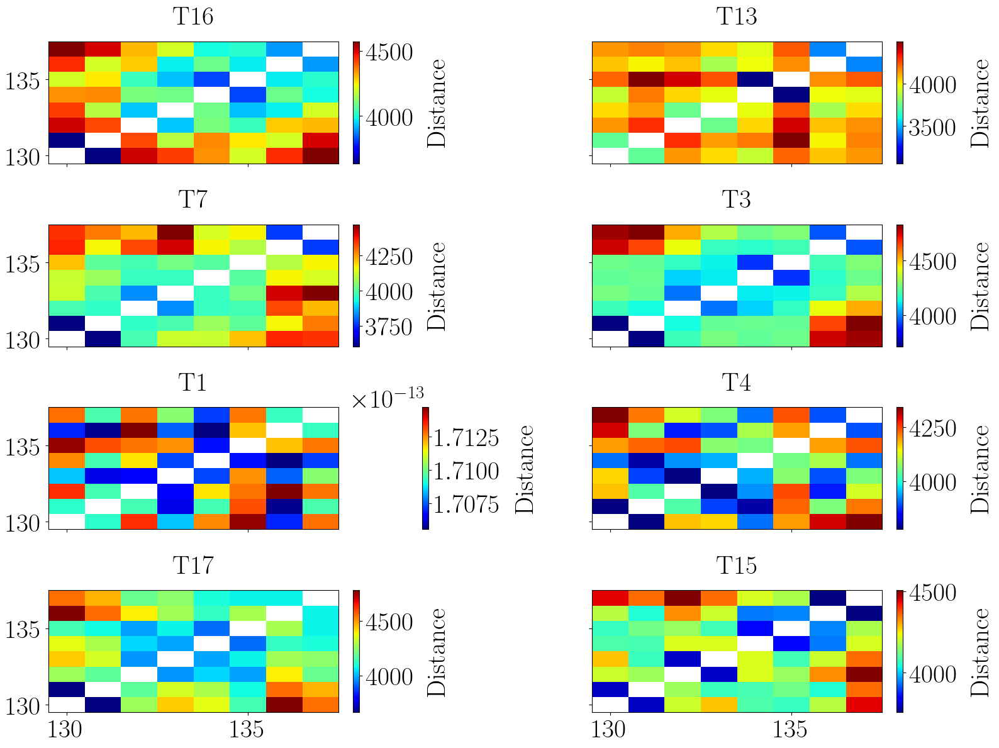

In [122]:
fig, axs = plt.subplots(
    nrows=len(tossit_n_visu) // 2,
    ncols=2,
    figsize=(16, 12),
    sharex=True,
    sharey=True,
)

# Iterate over all tossits and compute RTF
for i_tossit, tossit_n in enumerate(tossit_n_visu):
    ax = axs.flat[i_tossit]
    im = ax.pcolormesh(
        sus_n_visu,
        sus_n_visu,
        distance[tossit_n],
        cmap="jet",
        shading="auto",
        # vmin=np.percentile(distance[tossit_n], 15),
        # vmax=np.percentile(distance[tossit_n], 95)
    )
    ax.set_title(f"T{tossit_n}")
    plt.colorbar(im, ax=ax, label="Distance")

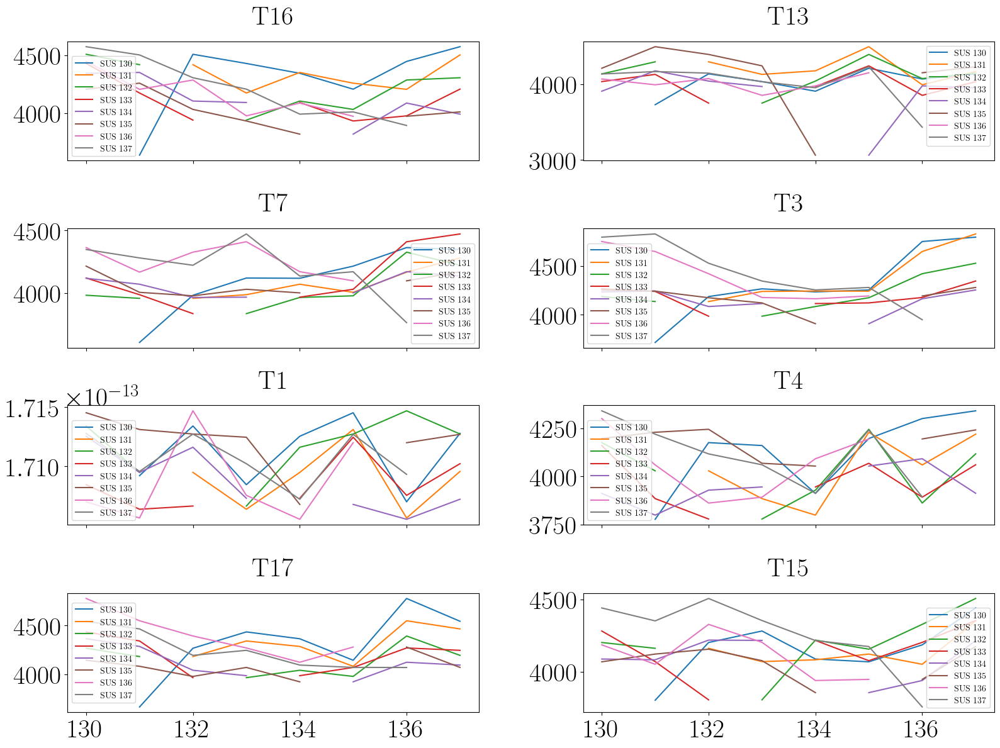

In [124]:
fig, axs = plt.subplots(
    nrows=len(tossit_n_visu) // 2,
    ncols=2,
    figsize=(16, 12),
    sharex=True,
    sharey=False,
)

# Iterate over all tossits and compute RTF
for i_tossit, tossit_n in enumerate(tossit_n_visu):
    ax = axs.flat[i_tossit]

    for i_sus, sus_n in enumerate(sus_n_visu):
        ax.plot(sus_n_visu, distance[tossit_n][i_sus, :], label=f"SUS {sus_n}")

    ax.legend(fontsize=10)
    ax.set_title(f"T{tossit_n}")


On retrouve notre problématique d'évaluation de la distance. 
